# Smartphone touch experiments: Sweet Spot, 6 October 2026

**Research purpose.** Describe recorded touchscreen contacts, identify spatially repeated contacts, and document the limitations of the logging process for a scientific article.
The Sweet Spot condition is identified by the operator as a comfortable configuration of both robots; the JSONL does not contain robot poses or joint angles.

This notebook is the executable analysis. Raw measurements, operator annotations, derived classifications, and hypotheses are reported separately.
Source: `touch_results_2026-10-06-sweetspot.jsonl`. Each line is an event, not necessarily a touchscreen contact.
Session numbers follow the first recorded event chronologically and retain the original numbering after exclusion.
Timestamps in the raw file are UTC; local times use **America/Recife (UTC−03:00)**.

Run all cells in order from the repository root. Dependencies and execution instructions are in `README.md`.
Outputs are written to `sweetspot_analysis/`; the source JSONL is never edited.

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime, timedelta
from zoneinfo import ZoneInfo
import csv
import hashlib
import html
import json
import math
import subprocess
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
%matplotlib inline

BASE = Path.cwd()
SOURCE = BASE / "touch_results_2026-10-06-sweetspot.jsonl"
if not SOURCE.exists():
    raise FileNotFoundError("Run the notebook from the phone-test-results repository root.")
OUTPUT = BASE / "sweetspot_analysis"
OUTPUT.mkdir(exist_ok=True)
LOCAL_TIMEZONE = ZoneInfo("America/Recife")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .2})

def show_table(rows, fields=None):
    if not rows:
        display(Markdown("No records."))
        return
    fields = fields or list(rows[0])
    def esc(v):
        return html.escape(str(v))
    display(HTML("<div style='overflow-x:auto'><table><thead><tr>" +
                 "".join(f"<th>{esc(c)}</th>" for c in fields) + "</tr></thead><tbody>" +
                 "".join("<tr>" + "".join(f"<td>{esc(l.get(c, ''))}</td>" for c in fields) + "</tr>" for l in rows) +
                 "</tbody></table></div>"))

def write_csv(name, rows, fields=None):
    fields = fields or (list(rows[0]) if rows else [])
    with (OUTPUT / name).open('w', newline='', encoding='utf-8') as f:
        writer = csv.DictWriter(f, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)

def save_figure(name, fig):
    fig.savefig(OUTPUT / name, dpi=300, bbox_inches="tight")
    if "/" not in name:
        fig.savefig(OUTPUT / Path(name).with_suffix(".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(fig)

raw = SOURCE.read_bytes()
records = []
for line_number, text in enumerate(raw.decode("utf-8").splitlines(), 1):
    if text.strip():
        r = json.loads(text)
        r["source_line"] = line_number
        r["timestamp"] = datetime.fromisoformat(r["date_time"].replace("Z", "+00:00"))
        records.append(r)
assert records, "The source contains no events."
records.sort(key=lambda r: (r["timestamp"], r["source_line"]))
groups = defaultdict(list)
for r in records:
    groups[r["session_id"]].append(r)
session_order = sorted(groups, key=lambda s: groups[s][0]["timestamp"])
session_number = {s: i for i, s in enumerate(session_order, 1)}
touches = [r for r in records if r["actual_touch_x"] is not None and r["actual_touch_y"] is not None]
print(f"{len(records)} events; {len(groups)} sessions; {len(touches)} contacts with coordinates.")
print("SHA-256:", hashlib.sha256(raw).hexdigest())
print("Recorded event interval:", records[0]["timestamp"].astimezone(LOCAL_TIMEZONE).isoformat(), "to", records[-1]["timestamp"].astimezone(LOCAL_TIMEZONE).isoformat())
print("App outcomes:", dict(Counter(r["result"] for r in records)))
second_source = BASE / "touch_results_after_app_update_2026-10-06.jsonl"
print("After-update file:", f"{second_source.stat().st_size} bytes" if second_source.exists() else "unrecorded")

177 events; 20 sessions; 137 contacts with coordinates.
SHA-256: 290accd48b1739358913f6846d241b868f7a73a8317a14dd1b178490747f67f5
Recorded event interval: 2026-10-06T14:40:15.572563-03:00 to 2026-10-06T15:37:46.275336-03:00
App outcomes: {'hit': 111, 'miss': 26, 'no_touch': 40}
After-update file: 0 bytes


## 1. Data integrity and provenance

Check unique event identifiers, one-to-one session/test identifiers, within-session configuration and geometry, paired null coordinates, and consistency between geometry and reported hit/miss outcomes.
Distances are recalculated with an absolute tolerance of **0.001 px**, accommodating Android floating-point rounding.
Repeated target IDs are retained. A false timeout flag does not establish session completion.
The schema's expected identifiers are constructed from `trio-NNN-{red,green,blue}`; operator corrections are applied separately below.

In [2]:
assert len({r["event_id"] for r in records}) == len(records), "Duplicate event_id"
assert len({r["test_id"] for r in records}) == len(groups), "test_id reused across sessions"
for sid, rs in groups.items():
    assert len({r["test_id"] for r in rs}) == 1
    assert len({json.dumps(r["configuration"], sort_keys=True) for r in rs}) == 1
    config = rs[0]["configuration"]
    assert config["target_count"] == 3 * config["rgb_trios_per_spawn"]
    expected_ids = {f"trio-{i:03d}-{color}" for i in range(1, config["rgb_trios_per_spawn"] + 1) for color in ("red", "green", "blue")}
    assert {r["target_id"] for r in rs} <= expected_ids
    geometry = defaultdict(set)
    for r in rs:
        geometry[r["target_id"]].add((r["target_center_x"], r["target_center_y"], r["target_radius"]))
    assert all(len(v) == 1 for v in geometry.values()), "Target geometry changed within a session"
for r in records:
    assert (r["actual_touch_x"] is None) == (r["actual_touch_y"] is None)
    assert r["response_time_ms"] >= 0 and r["target_radius"] > 0
    assert 0 <= r["target_center_x"] <= r["screen_width"]
    assert 0 <= r["target_center_y"] <= r["screen_height"]
    assert math.isclose(r["target_diameter"], 2 * r["target_radius"])
    if r["actual_touch_x"] is None:
        assert r["result"] == "no_touch" and r["distance_to_center"] is None and not r["inside_target"]
    else:
        d = math.hypot(r["actual_touch_x"] - r["target_center_x"], r["actual_touch_y"] - r["target_center_y"])
        assert math.isclose(d, r["distance_to_center"], abs_tol=.001)
        assert r["inside_target"] == (d <= r["target_radius"])
        assert r["result"] == ("hit" if r["inside_target"] else "miss")
print("Data integrity checks passed.")
print("Screen dimensions:", sorted({(r['screen_width'], r['screen_height']) for r in records}))
print("Timeout flags:", sum(r["timed_out"] for r in records))
print("previous_attempts matches the event index in every session:",
      all([r["previous_attempts_in_session"] for r in groups[s]] == list(range(len(groups[s]))) for s in session_order))

Data integrity checks passed.
Screen dimensions: [(1080, 2400)]
Timeout flags: 0
previous_attempts matches the event index in every session: True


## 2. Operator decisions and analysis population

**Retrospective operator exclusions:** sessions **3, 4, 6, 7, and 9** were identified by the operator as interrupted, invalid trials.
This is not a threshold chosen by the analyst from the number of contacts. Excluded records remain available in `excluded_sessions/`, with their original identifiers.

**Operator-reported completion and target count:** sessions **12 and 13** are retained as completed trials with **six displayed targets (two trios)**, as confirmed by the operator.
Their raw configuration records **nine targets and three trios**. The primary target denominator uses the operator-confirmed six; the raw count remains available for a sensitivity comparison.
The identities of the six recorded targets are retained without renumbering. This does not independently establish the identity of every displayed target.

Recorded identifiers in session 12 correspond to trios 1 and 3; session 13 contains three green, two red, and one blue identifiers.
Thus, the identifiers alone do not verify a layout consisting of two complete RGB trios. The operator's six-target statement is accepted as an external annotation, and this unresolved metadata discrepancy is retained.
No target-count corrections are inferred for any other session.
The 15 retained sessions are the **operator-selected analysis population**; completeness is not established from the hit rate.

In [3]:
EXCLUDED_SESSION_NUMBERS = {3, 4, 6, 7, 9}
OPERATOR_TARGET_COUNTS = {12: 6, 13: 6}
original_records = records.copy()
original_groups = dict(groups)
original_order = session_order.copy()
assert EXCLUDED_SESSION_NUMBERS <= set(session_number.values())
EXCLUDED_OUTPUT = OUTPUT / 'excluded_sessions'
EXCLUDED_OUTPUT.mkdir(exist_ok=True)
excluded_sessions = []
for sid in original_order:
    if session_number[sid] not in EXCLUDED_SESSION_NUMBERS:
        continue
    rs = original_groups[sid]
    excluded_sessions.append(dict(session_number=session_number[sid], session_id=sid, test_id=rs[0]['test_id'],
        reason='Interrupted trial; excluded retrospectively by the operator',
        logged_target_count=rs[0]['configuration']['target_count'], events=len(rs),
        touches=sum(r['actual_touch_x'] is not None for r in rs),
        hits=sum(r['result'] == 'hit' for r in rs), misses=sum(r['result'] == 'miss' for r in rs),
        no_touch=sum(r['result'] == 'no_touch' for r in rs)))
excluded_line_numbers = {r['source_line'] for r in original_records if session_number[r['session_id']] in EXCLUDED_SESSION_NUMBERS}
source_lines = raw.splitlines(keepends=True)
(EXCLUDED_OUTPUT / 'original_events.jsonl').write_bytes(b''.join(line for i, line in enumerate(source_lines, 1) if i in excluded_line_numbers))
(OUTPUT / 'touch_results_sweetspot_valid.jsonl').write_bytes(b''.join(line for i, line in enumerate(source_lines, 1) if line.strip() and i not in excluded_line_numbers))
write_csv('excluded_sessions/sessions.csv', excluded_sessions)
session_order = [sid for sid in original_order if session_number[sid] not in EXCLUDED_SESSION_NUMBERS]
groups = {sid: original_groups[sid] for sid in session_order}
records = [r for r in original_records if r['session_id'] in groups]
touches = [r for r in records if r['actual_touch_x'] is not None]
assert len(records) + len(excluded_line_numbers) == len(original_records)
assert len(groups) + len(excluded_sessions) == len(original_groups)

def expected_target_ids(sid):
    rs = original_groups[sid]
    if session_number[sid] in OPERATOR_TARGET_COUNTS:
        ids = sorted({r['target_id'] for r in rs})
        assert len(ids) == OPERATOR_TARGET_COUNTS[session_number[sid]]
        return ids
    config = rs[0]['configuration']
    return sorted(f"trio-{i:03d}-{color}" for i in range(1, config['rgb_trios_per_spawn'] + 1)
                  for color in ('red', 'green', 'blue'))

operator_annotations = []
for sid in session_order:
    if session_number[sid] not in OPERATOR_TARGET_COUNTS:
        continue
    ids = expected_target_ids(sid)
    color_counts = Counter(tid.rsplit('-', 1)[-1] for tid in ids)
    operator_annotations.append(dict(session_number=session_number[sid], session_id=sid,
        logged_target_count=original_groups[sid][0]['configuration']['target_count'],
        effective_target_count=OPERATOR_TARGET_COUNTS[session_number[sid]], operator_reported_trio_count=2,
        completion_basis='Operator confirms completed trial with six displayed targets',
        annotation_source='Operator clarification in the analysis conversation',
        logged_red_ids=color_counts['red'], logged_green_ids=color_counts['green'], logged_blue_ids=color_counts['blue'],
        target_ids=';'.join(ids), metadata_discrepancy='Raw target count and/or identifiers do not verify the reported two-trio layout'))
write_csv('operator_annotations.csv', operator_annotations)
show_table(excluded_sessions)
show_table(operator_annotations)
print(f'Retained: {len(groups)} sessions, {len(records)} events, {len(touches)} recorded contacts.')
print(f'Excluded: {len(excluded_sessions)} sessions, {len(excluded_line_numbers)} events. Original session numbering retained.')


session_number,session_id,test_id,reason,logged_target_count,events,touches,hits,misses,no_touch
3,2b53e46e-4e49-4820-93a9-6c4edf8cac94,6dfaba85-7784-4d1c-9153-588822e7ee3d,Interrupted trial; excluded retrospectively by the operator,12,1,1,0,1,0
4,bf8e71e5-5c28-400b-a3f7-145561d2774f,ba2db20e-eb9c-4350-ad3e-0ab771083ba6,Interrupted trial; excluded retrospectively by the operator,12,1,1,0,1,0
6,d0437ec4-5e99-4090-af84-f0aad33b75b5,fef809f4-8c67-4203-b292-b26e2dc8dd8f,Interrupted trial; excluded retrospectively by the operator,12,1,1,0,1,0
7,71dbf087-c4b8-4aab-8ca0-895bd33fd4c6,b87f7df5-2bb7-447f-9076-080bc4bd1d4f,Interrupted trial; excluded retrospectively by the operator,9,1,1,0,1,0
9,7fc20fd5-ead3-41a7-99fb-3cd055b9e6c2,bd7d6332-f5b5-411b-b9fd-176c4427d6ad,Interrupted trial; excluded retrospectively by the operator,9,10,1,0,1,9


session_number,session_id,logged_target_count,effective_target_count,operator_reported_trio_count,completion_basis,annotation_source,logged_red_ids,logged_green_ids,logged_blue_ids,target_ids,metadata_discrepancy
12,277529fc-a0e6-44b5-b811-f69de2f4bf86,9,6,2,Operator confirms completed trial with six displayed targets,Operator clarification in the analysis conversation,2,2,2,trio-001-blue;trio-001-green;trio-001-red;trio-003-blue;trio-003-green;trio-003-red,Raw target count and/or identifiers do not verify the reported two-trio layout
13,65031c8f-8bbe-4e4a-8673-6a2551c16c0d,9,6,2,Operator confirms completed trial with six displayed targets,Operator clarification in the analysis conversation,2,3,1,trio-001-green;trio-002-green;trio-002-red;trio-003-blue;trio-003-green;trio-003-red,Raw target count and/or identifiers do not verify the reported two-trio layout


Retained: 15 sessions, 163 events, 132 recorded contacts.
Excluded: 5 sessions, 14 events. Original session numbering retained.


## 3. Session and target audit

Per-target states are mutually exclusive: `hit` (at least one recorded hit), `miss_without_hit`, `no_touch_only`, or `unrecorded`.
The separate `hit_and_no_touch` flag preserves mixed event histories; it is not an additional failed target.
A miss followed by a hit is an observed event sequence, not proof of an intentional retry.

The **count-ceiling flag** is descriptive: recorded contacts equal the effective target count, at least one miss exists, and not all targets have a recorded hit.
This is compatible with the reported logger behavior but does not prove censoring. `missing_target_records` refers to expected IDs absent under the documented count assumptions, not directly to trial interruption.
For sessions 12 and 13, `completion_basis` records operator confirmation rather than inferring incomplete execution from the nine-target configuration.

In [4]:
sessions, targets = [], []
for sid in session_order:
    rs = groups[sid]
    config = rs[0]["configuration"]
    by_target = defaultdict(list)
    for r in rs:
        by_target[r["target_id"]].append(r)
    expected_ids = expected_target_ids(sid)
    n = len(expected_ids)
    target_summaries = []
    for tid in expected_ids:
        ev = by_target.get(tid, [])
        results = [r["result"] for r in ev]
        hit = "hit" in results
        miss = "miss" in results
        no_touch_seen = "no_touch" in results
        status = "hit" if hit else "miss_without_hit" if miss else "no_touch_only" if no_touch_seen else "unrecorded"
        a = dict(session_number=session_number[sid], session_id=sid, target_id=tid, status=status,
                 events=len(ev), touches=sum(r["actual_touch_x"] is not None for r in ev),
                 miss_followed_by_hit=hit and any(r["result"] == "miss" for r in ev[:next((j for j, r in enumerate(ev) if r["result"] == "hit"), len(ev))]),
                 hit_and_no_touch=hit and no_touch_seen, result_sequence=" → ".join(results))
        targets.append(a)
        target_summaries.append(a)
    counts = Counter(r["result"] for r in rs)
    statuses = Counter(a["status"] for a in target_summaries)
    nt = counts["hit"] + counts["miss"]
    ceiling_flags = nt == n and counts["miss"] > 0 and statuses["hit"] < n
    s = dict(session_number=session_number[sid], session_id=sid, test_id=rs[0]["test_id"],
             first_event_local=rs[0]["timestamp"].astimezone(LOCAL_TIMEZONE).isoformat(),
             last_event_local=rs[-1]["timestamp"].astimezone(LOCAL_TIMEZONE).isoformat(),
             event_span_s=round((rs[-1]["timestamp"] - rs[0]["timestamp"]).total_seconds(), 3),
             radius_dp=rs[0]["target_radius_dp"], effective_target_count=n, logged_target_count=config["target_count"],
             configuration_discrepancy=n != config["target_count"], target_count_source="operator" if session_number[sid] in OPERATOR_TARGET_COUNTS else "JSON", completion_basis='operator_confirmed' if session_number[sid] in OPERATOR_TARGET_COUNTS else 'all_expected_ids_recorded' if len(by_target) == n else 'not_established', events=len(rs), touches=nt,
             recorded_target_count=len(by_target), hits=counts["hit"], misses=counts["miss"], no_touch=counts["no_touch"],
             targets_with_hit=statuses["hit"], targets_with_miss_without_hit=statuses["miss_without_hit"],
             targets_with_no_touch_only=statuses["no_touch_only"], targets_without_records=statuses["unrecorded"],
             targets_with_miss_followed_by_hit=sum(a["miss_followed_by_hit"] for a in target_summaries),
             hit_and_no_touch=sum(a["hit_and_no_touch"] for a in target_summaries),
             count_ceiling_flag=ceiling_flags, missing_target_records=statuses["unrecorded"] > 0,
             touch_count_exceeds_effective_targets=nt > n)
    sessions.append(s)

show_table(sessions, ["session_number", "first_event_local", "radius_dp", "effective_target_count", "logged_target_count", "events", "touches", "hits", "misses", "no_touch", "targets_without_records", "hit_and_no_touch", "count_ceiling_flag"])
write_csv("sessions.csv", sessions)
write_csv("targets.csv", targets)

session_number,first_event_local,radius_dp,effective_target_count,logged_target_count,events,touches,hits,misses,no_touch,targets_without_records,hit_and_no_touch,count_ceiling_flag
1,2026-10-06T14:40:15.572563-03:00,50,6,6,7,6,5,1,1,0,0,True
2,2026-10-06T14:41:22.301071-03:00,50,12,12,13,12,12,0,1,0,1,False
5,2026-10-06T14:43:59.547583-03:00,45,12,12,15,12,10,2,3,0,1,True
8,2026-10-06T14:47:14.838751-03:00,40,9,9,10,9,9,0,1,0,1,False
10,2026-10-06T14:49:28.199537-03:00,40,9,9,10,9,9,0,1,0,1,False
11,2026-10-06T14:51:26.843567-03:00,35,9,9,11,9,8,1,2,0,1,True
12,2026-10-06T14:59:03.599587-03:00,35,6,9,6,6,5,1,0,0,0,True
13,2026-10-06T15:01:28.657852-03:00,35,6,9,6,6,6,0,0,0,0,False
14,2026-10-06T15:14:18.825647-03:00,35,9,9,12,9,7,2,3,0,1,True
15,2026-10-06T15:24:52.838439-03:00,35,9,9,11,9,8,1,2,0,1,True


## 4. Can the logging-limit change be located?

Direct evidence would require a session recording more contacts with non-null coordinates than its target count.
An additional `no_touch` row is not an additional contact. `previous_attempts_in_session` behaves as an event index in these logs and cannot substitute for contact count.
The analysis reports observable counts; it cannot reconstruct contacts never logged.


**The logger-change session cannot be established from this dataset.**
No retained session contains a contact beyond its effective target count (0 such contacts).
13 sessions have more event rows than targets; the extra rows are manual no_touch events.
This absence is not proof that a ceiling remained active: an additional detectable contact may not have occurred.

| Descriptive flag | Session numbers | Sessions |
|---|---|---:|
| Contact count equals target count, with misses | 1, 5, 11, 12, 14, 15, 18, 20 | 8/15 |
| Expected target IDs without records, under analysis assumptions | none | 0/15 |
| Target has both hit and no_touch events | 2, 5, 8, 10, 11, 14, 15, 18 | 8/15 |

Flags can overlap and do not establish censoring or mechanical failure.
The number of sessions with contacts actually lost by the logger is **unknown**.
There are 4 miss-followed-by-hit target histories; all occur within the target-count limit.


session_number,session_id,first_event_local,effective_target_count,touches,misses,targets_with_hit
1,bba6558a-2cdd-42d7-9e0a-ab8cfb3cf138,2026-10-06T14:40:15.572563-03:00,6,6,1,5
5,a062dec0-466b-4c6b-93a3-beac4c2567fa,2026-10-06T14:43:59.547583-03:00,12,12,2,10
11,03e7ef75-2c8e-44a6-9779-2045bcc52a5b,2026-10-06T14:51:26.843567-03:00,9,9,1,8
12,277529fc-a0e6-44b5-b811-f69de2f4bf86,2026-10-06T14:59:03.599587-03:00,6,6,1,5
14,9ecbaf6c-0bb3-4e4c-b9db-d990c214fb05,2026-10-06T15:14:18.825647-03:00,9,9,2,7
15,a8626db1-7147-493b-9c73-e8e44ded9884,2026-10-06T15:24:52.838439-03:00,9,9,1,8
18,38a197b6-d1c7-4223-955c-9e78269cf776,2026-10-06T15:30:58.721174-03:00,9,9,1,8
20,b7c1b59e-1e8d-468b-90c0-21ad617d0e20,2026-10-06T15:36:57.028824-03:00,9,9,4,5


session_number,target_id,result_sequence
5,trio-003-green,miss → hit
5,trio-003-red,miss → hit
14,trio-002-blue,miss → hit
15,trio-002-blue,miss → hit


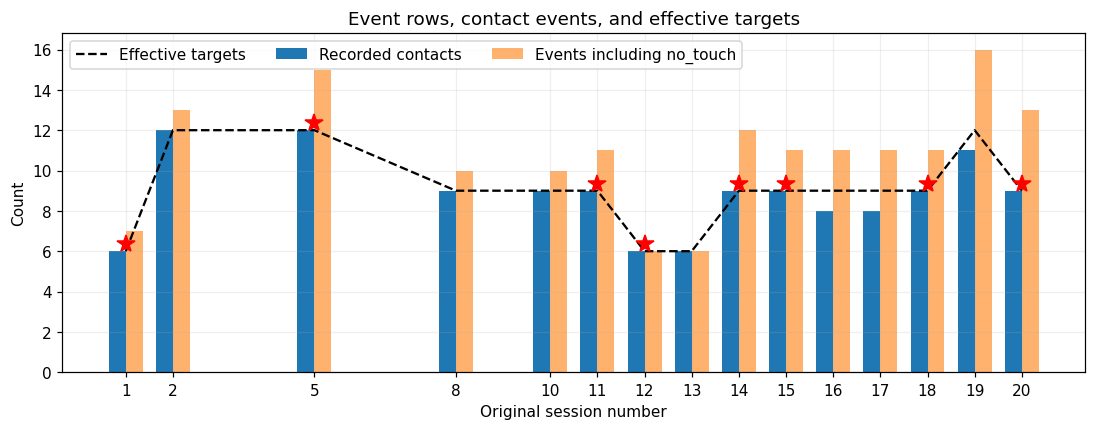

In [5]:
beyond_target_count = []
for sid in session_order:
    contact_index = 0
    n = len(expected_target_ids(sid))
    for r in groups[sid]:
        if r['actual_touch_x'] is not None:
            contact_index += 1
            if contact_index > n:
                beyond_target_count.append(dict(session_number=session_number[sid], contact_index=contact_index,
                    target_id=r['target_id'], result=r['result'], source_line=r['source_line']))
ceiling_flags = [s for s in sessions if s['count_ceiling_flag']]
missing_flags = [s for s in sessions if s['missing_target_records']]
hit_no_touch_flags = [s for s in sessions if s['hit_and_no_touch']]
miss_then_hit_targets = [a for a in targets if a['miss_followed_by_hit']]
list_session_numbers = lambda ss: ', '.join(str(s['session_number']) for s in ss) or 'none'
display(Markdown(f"""
**The logger-change session cannot be established from this dataset.**
No retained session contains a contact beyond its effective target count ({len(beyond_target_count)} such contacts).
{sum(s['events'] > s['effective_target_count'] for s in sessions)} sessions have more event rows than targets; the extra rows are manual no_touch events.
This absence is not proof that a ceiling remained active: an additional detectable contact may not have occurred.

| Descriptive flag | Session numbers | Sessions |
|---|---|---:|
| Contact count equals target count, with misses | {list_session_numbers(ceiling_flags)} | {len(ceiling_flags)}/{len(sessions)} |
| Expected target IDs without records, under analysis assumptions | {list_session_numbers(missing_flags)} | {len(missing_flags)}/{len(sessions)} |
| Target has both hit and no_touch events | {list_session_numbers(hit_no_touch_flags)} | {len(hit_no_touch_flags)}/{len(sessions)} |

Flags can overlap and do not establish censoring or mechanical failure.
The number of sessions with contacts actually lost by the logger is **unknown**.
There are {len(miss_then_hit_targets)} miss-followed-by-hit target histories; all occur within the target-count limit.
"""))
show_table(ceiling_flags, ['session_number', 'session_id', 'first_event_local', 'effective_target_count', 'touches', 'misses', 'targets_with_hit'])
show_table(miss_then_hit_targets, ['session_number', 'target_id', 'result_sequence'])
write_csv('count_ceiling_flags.csv', ceiling_flags)
write_csv('missing_target_flags.csv', missing_flags, fields=list(sessions[0]))
write_csv('targets_with_hit_and_no_touch.csv', [a for a in targets if a['hit_and_no_touch']])
fig, ax = plt.subplots(figsize=(12, 4))
x = np.array([s['session_number'] for s in sessions])
ax.plot(x, [s['effective_target_count'] for s in sessions], 'k--', label='Effective targets')
ax.bar(x - .18, [s['touches'] for s in sessions], .36, label='Recorded contacts')
ax.bar(x + .18, [s['events'] for s in sessions], .36, label='Events including no_touch', alpha=.6)
for s in ceiling_flags:
    ax.plot(s['session_number'], s['touches'] + .35, 'r*', markersize=12)
ax.set(xticks=x, xlabel='Original session number', ylabel='Count', title='Event rows, contact events, and effective targets')
ax.legend(ncol=3)
save_figure('01_session_counts.png', fig)

### Local software context (not the installed APK)

The neighboring Android and ROS repositories are optional context. File hashes and Git revision are recorded if available.
There is no APK version in the event data. A Git commit date does not identify installation time, and current source code cannot establish which behavior operated during a trial.

In [6]:
APP = BASE.parent / 'robot-touch-test-app'
VIEW = APP / 'app/src/main/java/com/pcgr/robottouchtest/RobotTouchTestView.kt'
ROBOT = BASE.parent / 'denso_robot_ros2/denso_collab/src/move_to_screen_standoff.cpp'
software_context = {}
for name, path in [('android_view', VIEW), ('robot_sequence', ROBOT)]:
    if path.exists():
        software_context[name] = {'path': str(path), 'sha256': hashlib.sha256(path.read_bytes()).hexdigest()}
if VIEW.exists():
    revision = subprocess.run(['git', '-C', str(APP), 'rev-parse', 'HEAD'], capture_output=True, text=True)
    software_context['android_git_revision'] = revision.stdout.strip() if revision.returncode == 0 else None
    display(Markdown("""
The inspected local Android view finishes according to completed targets. After a miss it ignores surface touches while waiting for operator advance, which skips that target.
The logs show miss-to-hit histories, hit-to-no_touch histories, and event-index behavior that do not fully match that implementation.
Therefore, this source is contextual evidence only and cannot identify the APK used or date a change during the recorded sessions.
"""))
if ROBOT.exists():
    display(Markdown("""
The local denso_collab sequence can stop if movement or contact handling fails. A /touch_detected signal does not guarantee an Android touchscreen event.
No synchronized robot/contact-sensor logs are included here, so missed logging, physical failure, and interrupted execution cannot be distinguished from these records alone.
"""))
print(json.dumps(software_context, indent=2))


The inspected local Android view finishes according to completed targets. After a miss it ignores surface touches while waiting for operator advance, which skips that target.
The logs show miss-to-hit histories, hit-to-no_touch histories, and event-index behavior that do not fully match that implementation.
Therefore, this source is contextual evidence only and cannot identify the APK used or date a change during the recorded sessions.



The local denso_collab sequence can stop if movement or contact handling fails. A /touch_detected signal does not guarantee an Android touchscreen event.
No synchronized robot/contact-sensor logs are included here, so missed logging, physical failure, and interrupted execution cannot be distinguished from these records alone.


{
  "android_view": {
    "path": "/home/pcgr/Code/denso/robot-touch-test-app/app/src/main/java/com/pcgr/robottouchtest/RobotTouchTestView.kt",
    "sha256": "1d441b53771aeb85bf39cbb49e97bb6a917631552d6d72e7c0a03f969dfdd07c"
  },
  "robot_sequence": {
    "path": "/home/pcgr/Code/denso/denso_robot_ros2/denso_collab/src/move_to_screen_standoff.cpp",
    "sha256": "b06aef6805b291cf4e4162b9690e014baa9a6dcef8d7baf5e6fbc3e49b018b73"
  },
  "android_git_revision": "2bb4a81c270657b4b4860a3f5151d8de777b7152"
}


## 5. Observed outcomes and explicit denominators

**Recorded-contact hit rate** = hit events / contact events with coordinates. This describes recorded app outcomes, including repeat contacts; it is not a rate of independent robot actions.

**Observed target hit coverage** = distinct targets with at least one hit / effective targets in retained sessions. Multiple contacts do not duplicate targets.
The effective denominator incorporates the two operator corrections. A separate calculation uses the unmodified JSON configuration count to expose sensitivity to those corrections.

All contact events, including rapid repeated-contact candidates and extreme errors, remain in the primary metrics.
No unobserved contact is imputed, and `no_touch` is not automatically interpreted as a mechanical failure.
The resulting metrics are descriptive of this selected experimental series, not estimates from a randomized or balanced study.

sample,sessions,effective_target_count,touches,hits,recorded_touch_hit_rate,targets_with_hit,observed_target_hit_coverage,miss_without_hit,no_touch_only,unrecorded_targets
Retained sessions; operator-corrected target counts,15,135,132,111,0.8409090909090909,111,0.8222222222222222,16,8,0


basis,numerator,denominator,fraction
Operator-corrected effective target count,111,135,0.8222222222222222
Unmodified JSON configuration target count,111,141,0.7872340425531915


sample,sessions,effective_target_count,touches,hits,recorded_touch_hit_rate,targets_with_hit,observed_target_hit_coverage,miss_without_hit,no_touch_only,unrecorded_targets,median_distance_px
50 dp,2,18,18,17,0.9444444444444444,17,0.9444444444444444,1,0,0,38.72
45 dp,1,12,12,10,0.8333333333333334,10,0.8333333333333334,0,2,0,51.86
40 dp,2,18,18,18,1.0,18,1.0,0,0,0,37.56
35 dp,5,39,39,34,0.8717948717948718,34,0.8717948717948718,3,2,0,46.46
30 dp,4,39,36,27,0.75,27,0.6923076923076923,8,4,0,45.72
25 dp,1,9,9,5,0.5555555555555556,5,0.5555555555555556,4,0,0,40.73


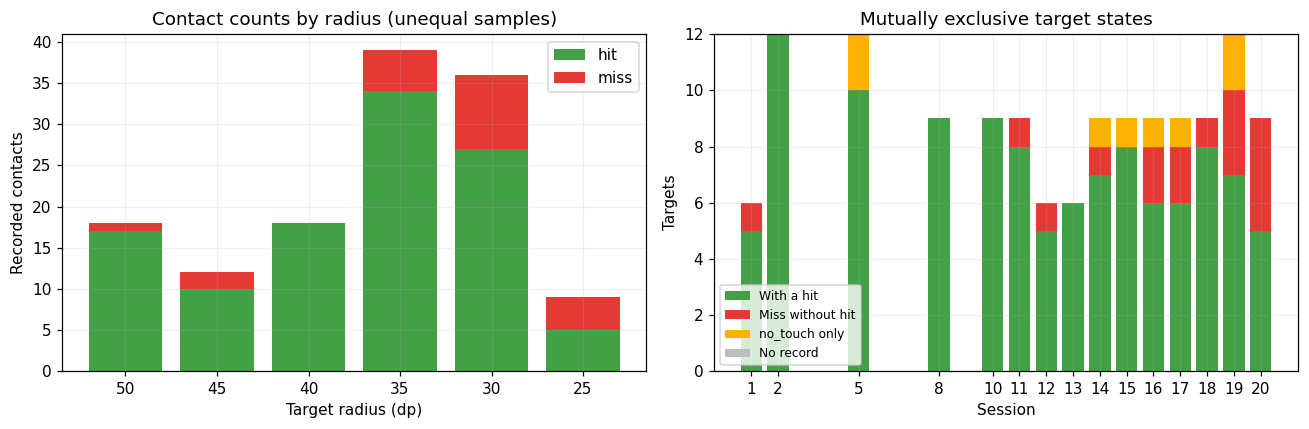

In [7]:
def metrics(name, selected):
    ids = {s['session_id'] for s in selected}
    aa = [a for a in targets if a['session_id'] in ids]
    tt = [r for r in touches if r['session_id'] in ids]
    hits = sum(r['result'] == 'hit' for r in tt)
    ah = sum(a['status'] == 'hit' for a in aa)
    return dict(sample=name, sessions=len(ids), effective_target_count=len(aa), touches=len(tt), hits=hits,
                recorded_touch_hit_rate=hits / len(tt) if tt else '—',
                targets_with_hit=ah, observed_target_hit_coverage=ah / len(aa) if aa else '—',
                miss_without_hit=sum(a['status'] == 'miss_without_hit' for a in aa),
                no_touch_only=sum(a['status'] == 'no_touch_only' for a in aa),
                unrecorded_targets=sum(a['status'] == 'unrecorded' for a in aa))

sample_summary = [metrics('Retained sessions; operator-corrected target counts', sessions)]
raw_target_denominator = sum(s['logged_target_count'] for s in sessions)
denominator_sensitivity = [dict(basis='Operator-corrected effective target count', numerator=sample_summary[0]['targets_with_hit'], denominator=sum(s['effective_target_count'] for s in sessions), fraction=sample_summary[0]['observed_target_hit_coverage']),
    dict(basis='Unmodified JSON configuration target count', numerator=sample_summary[0]['targets_with_hit'], denominator=raw_target_denominator, fraction=sample_summary[0]['targets_with_hit'] / raw_target_denominator)]
write_csv('target_count_sensitivity.csv', denominator_sensitivity)
show_table(sample_summary)
show_table(denominator_sensitivity)
write_csv('sample_metrics.csv', sample_summary)

radius_summary = []
for radius in sorted({s['radius_dp'] for s in sessions}, reverse=True):
    ss = [s for s in sessions if s['radius_dp'] == radius]
    m = metrics(str(radius) + ' dp', ss)
    distance = [r['distance_to_center'] for r in touches if r['target_radius_dp'] == radius]
    m['median_distance_px'] = round(float(np.median(distance)), 2)
    radius_summary.append(m)
show_table(radius_summary)
write_csv('radius_metrics.csv', radius_summary)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
radii = sorted({s['radius_dp'] for s in sessions}, reverse=True)
xx = np.arange(len(radii))
for status, color in [('hit', '#43a047'), ('miss', '#e53935')]:
    values = [sum(r['result'] == status and r['target_radius_dp'] == d for r in touches) for d in radii]
    base = np.zeros(len(radii)) if status == 'hit' else np.array([sum(r['result'] == 'hit' and r['target_radius_dp'] == d for r in touches) for d in radii])
    axs[0].bar(xx, values, bottom=base, color=color, label=status)
axs[0].set(xticks=xx, xticklabels=radii, xlabel='Target radius (dp)', ylabel='Recorded contacts', title='Contact counts by radius (unequal samples)')
axs[0].legend()
base = np.zeros(len(sessions))
for key, label, color in [('targets_with_hit', 'With a hit', '#43a047'), ('targets_with_miss_without_hit', 'Miss without hit', '#e53935'), ('targets_with_no_touch_only', 'no_touch only', '#ffb300'), ('targets_without_records', 'No record', '#bdbdbd')]:
    y = np.array([s[key] for s in sessions])
    axs[1].bar(np.array([s['session_number'] for s in sessions]), y, bottom=base, label=label, color=color)
    base += y
axs[1].set(xlabel='Session', ylabel='Targets', title='Mutually exclusive target states', xticks=np.array([s['session_number'] for s in sessions]))
axs[1].legend(fontsize=8)
fig.tight_layout()
save_figure('02_observed_outcomes.png', fig)

### Interpretation of target sizes

Target radii were reduced over time, while target count and session conditions also varied. Size, time, and experimental conditions are confounded.
Size-specific rates are descriptive and must not be interpreted as a controlled causal comparison or evidence of a software improvement.
The 25 dp group contains one retained session. Pixels and dp are display units; a conversion to physical millimeters is not available in these logs.
No significance tests or confidence intervals treating contacts as independent trials are introduced: contacts are clustered within sessions and include repeats.

## 6. Spatial error and app target assignment

`dx = touch_x − target_center_x`, `dy = touch_y − target_center_y`; screen y increases downward.
Normalized error is center distance divided by target radius. Values ≤ 1 are inside the attributed circle.
The attributed target comes from the app and is not necessarily the target intended by the robot.
Means and medians are both reported; extreme distances are retained, not silently trimmed.
For sessions with geometry for all effective targets, check whether an app-labeled miss is inside another circle that already received a hit.

sample,n,median_dx_px,median_dy_px,median_distance_px,mean_distance_px,p90_distance_px
All recorded contacts,132,-19.84,-24.08,44.04,81.87,86.65
Hit contacts only,111,-18.17,-19.8,38.25,44.37,73.19


session_number,target_id,distance_px,inside_other_target,other_target_already_hit
5,trio-003-green,470.57327,trio-001-green,True
14,trio-002-blue,280.10907,trio-001-red,True
15,trio-002-blue,390.68777,trio-003-green,True


session_number,source_line,target_id,distance_px,radius_px,normalized_error
1,6,trio-002-blue,1495.9471,125,11.967576800000002
12,86,trio-003-green,1023.01575,87.5,11.691608571428572
20,173,trio-001-blue,639.8921,62.5,10.238273600000001
5,28,trio-003-green,470.57327,112.5,4.182873511111111
15,107,trio-002-blue,390.68777,87.5,4.465003085714286
14,93,trio-001-green,314.2024,87.5,3.5908845714285715
14,96,trio-002-blue,280.10907,87.5,3.201246514285714
5,23,trio-003-red,223.96541,112.5,1.9908036444444444
16,117,trio-002-red,91.73302,75,1.2231069333333333
11,71,trio-001-green,88.42419,87.5,1.0105621714285713


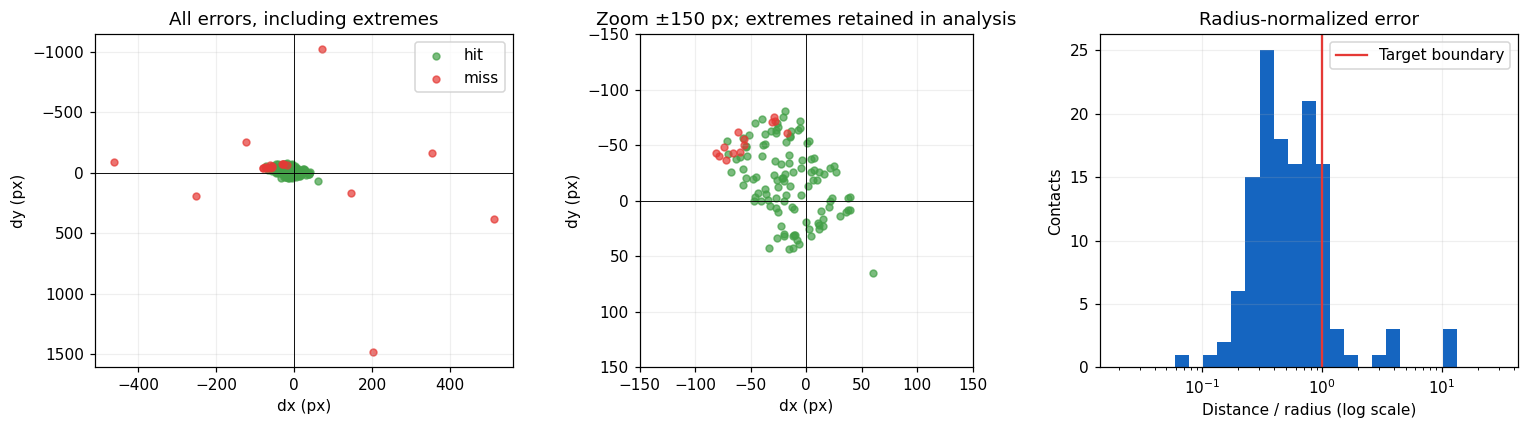


Median displacement: **-19.84 px in x**, **-24.08 px in y**.
Median radial distance: **44.04 px**; mean: **81.87 px**.
There are **3 app-labeled misses inside another target previously hit**.
These observations motivate an assignment/contact-repeat audit; they do not justify automatically applying the median offset as a physical calibration correction.


In [8]:
events = []
for sid in session_order:
    rs = groups[sid]
    geometries = {r['target_id']: r for r in rs}
    has_full_geometry = len(geometries) == len(expected_target_ids(sid))
    previously_hit = set()
    touch_index = 0
    for r in rs:
        is_touch = r['actual_touch_x'] is not None
        if is_touch:
            touch_index += 1
        dx = r['actual_touch_x'] - r['target_center_x'] if is_touch else None
        dy = r['actual_touch_y'] - r['target_center_y'] if is_touch else None
        other_target = ''
        other_hit = False
        if is_touch and has_full_geometry and r['result'] == 'miss':
            inside = [q['target_id'] for q in geometries.values() if q['target_id'] != r['target_id'] and
                      math.hypot(r['actual_touch_x'] - q['target_center_x'], r['actual_touch_y'] - q['target_center_y']) <= q['target_radius']]
            other_target = ', '.join(inside)
            other_hit = any(tid in previously_hit for tid in inside)
        events.append(dict(session_number=session_number[sid], session_id=sid, event_id=r['event_id'], source_line=r['source_line'],
                            event_time_utc=r['date_time'], event_time_local=r['timestamp'].astimezone(LOCAL_TIMEZONE).isoformat(), target_id=r['target_id'], result=r['result'],
                            touch_index=touch_index if is_touch else None, radius_dp=r['target_radius_dp'], radius_px=r['target_radius'],
                            target_x=r['target_center_x'], target_y=r['target_center_y'], touch_x=r['actual_touch_x'], touch_y=r['actual_touch_y'],
                            dx_px=dx, dy_px=dy, distance_px=r['distance_to_center'],
                            normalized_error=r['distance_to_center'] / r['target_radius'] if is_touch else None,
                            app_response_s=r['response_time_ms'] / 1000, previous_attempts=r['previous_attempts_in_session'],
                            inside_other_target=other_target, other_target_already_hit=other_hit))
        if r['result'] == 'hit':
            previously_hit.add(r['target_id'])
et = [e for e in events if e['touch_x'] is not None]
misses = [e for e in et if e['result'] == 'miss']
assignment_flags = [e for e in misses if e['inside_other_target']]
write_csv('events.csv', events)
write_csv('misses.csv', misses)

spatial_summary = []
for name, sample in [('All recorded contacts', et), ('Hit contacts only', [e for e in et if e['result'] == 'hit'])]:
    spatial_summary.append(dict(sample=name, n=len(sample),
        median_dx_px=round(float(np.median([e['dx_px'] for e in sample])), 2),
        median_dy_px=round(float(np.median([e['dy_px'] for e in sample])), 2),
        median_distance_px=round(float(np.median([e['distance_px'] for e in sample])), 2),
        mean_distance_px=round(float(np.mean([e['distance_px'] for e in sample])), 2),
        p90_distance_px=round(float(np.percentile([e['distance_px'] for e in sample], 90)), 2)))
show_table(spatial_summary)
show_table(assignment_flags, ['session_number', 'target_id', 'distance_px', 'inside_other_target', 'other_target_already_hit'])
show_table(sorted(misses, key=lambda e: e['distance_px'], reverse=True)[:10], ['session_number', 'source_line', 'target_id', 'distance_px', 'radius_px', 'normalized_error'])

fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for status, color in [('hit', '#43a047'), ('miss', '#e53935')]:
    ee = [e for e in et if e['result'] == status]
    for ax in axs[:2]:
        ax.scatter([e['dx_px'] for e in ee], [e['dy_px'] for e in ee], color=color, label=status, s=20, alpha=.7)
for ax in axs[:2]:
    ax.axhline(0, color='black', linewidth=.6)
    ax.axvline(0, color='black', linewidth=.6)
    ax.set(xlabel='dx (px)', ylabel='dy (px)')
    ax.invert_yaxis()
axs[0].set_title('All errors, including extremes')
axs[0].legend()
axs[1].set(xlim=(-150, 150), ylim=(150, -150), title='Zoom ±150 px; extremes retained in analysis')
axs[1].set_aspect('equal')
axs[2].hist([e['normalized_error'] for e in et], bins=np.geomspace(.02, 30, 28), color='#1565c0')
axs[2].axvline(1, color='#e53935', label='Target boundary')
axs[2].set(xscale='log', xlabel='Distance / radius (log scale)', ylabel='Contacts', title='Radius-normalized error')
axs[2].legend()
fig.tight_layout()
save_figure('03_spatial_errors.png', fig)

display(Markdown(f"""
Median displacement: **{spatial_summary[0]['median_dx_px']} px in x**, **{spatial_summary[0]['median_dy_px']} px in y**.
Median radial distance: **{spatial_summary[0]['median_distance_px']} px**; mean: **{spatial_summary[0]['mean_distance_px']} px**.
There are **{len(assignment_flags)} app-labeled misses inside another target previously hit**.
These observations motivate an assignment/contact-repeat audit; they do not justify automatically applying the median offset as a physical calibration correction.
"""))

## 7. Spatially repeated contacts

Compare all pairs of contact events within each retained session using **actual touch coordinates and UTC timestamps**.
Manual `no_touch` events have no contact coordinates and are excluded from the pair calculation.

Analyst-defined, adjustable exploratory criteria:

- Nearby contacts: separation ≤ **8 dp** (20 px for the recorded density of 2.5 px/dp).
- Rapid repeated-contact candidate: nearby contacts separated by ≤ **300 ms**.
- Same target region: both contacts have the same nearest recorded target and lie within its radius plus **20 dp**.

Assignment IDs do not determine proximity. Each pair retains both app assignments, raw timestamps, event/source identifiers, and positions.
The temporal criterion uses event timestamp differences, not `response_time_ms`. Sensitivity is shown at spatial thresholds of 5, 20, 50, and 100 px.
A close, rapid pair is consistent with a double click or repeated contact, but does not establish its physical cause. Pair counts are not counts of independent robot attempts.

In [9]:
NEARBY_DISTANCE_DP = 8
RAPID_CONTACT_WINDOW_MS = 300
TARGET_MARGIN_DP = 20
assert NEARBY_DISTANCE_DP > 0 and RAPID_CONTACT_WINDOW_MS > 0 and TARGET_MARGIN_DP >= 0

from itertools import combinations

def detect_pairs(rs):
    ts = [r for r in rs if r['actual_touch_x'] is not None]
    geometries = {r['target_id']: r for r in rs}
    density = rs[0]['target_radius'] / rs[0]['target_radius_dp']
    def target_distance(r, q):
        return math.hypot(r['actual_touch_x'] - q['target_center_x'], r['actual_touch_y'] - q['target_center_y'])
    nearest_targets = [min(geometries.values(), key=lambda q: target_distance(r, q)) for r in ts]
    pairs = []
    # ponytail: O(n²) for short sessions; use a spatial index if sessions become large.
    for (i, a), (j, b) in combinations(enumerate(ts, 1), 2):
        qa, qb = nearest_targets[i - 1], nearest_targets[j - 1]
        distance = math.hypot(a['actual_touch_x'] - b['actual_touch_x'], a['actual_touch_y'] - b['actual_touch_y'])
        dt = (b['timestamp'] - a['timestamp']).total_seconds() * 1000
        nearby = distance <= NEARBY_DISTANCE_DP * density
        same_target_region = (qa['target_id'] == qb['target_id'] and
                        target_distance(a, qa) <= qa['target_radius'] + TARGET_MARGIN_DP * density and
                        target_distance(b, qb) <= qb['target_radius'] + TARGET_MARGIN_DP * density)
        pairs.append(dict(touch_a=i, touch_b=j, distance_px=distance, interval_ms=dt,
            nearby=nearby, event_id_a=a['event_id'], event_id_b=b['event_id'],
            rapid_repeated_contact_candidate=nearby and 0 <= dt <= RAPID_CONTACT_WINDOW_MS,
            same_target_region=same_target_region, shared_nearest_target_id=qa['target_id'] if same_target_region else '',
            assigned_target_a=a['target_id'], assigned_target_b=b['target_id'],
            result_a=a['result'], result_b=b['result'],
            x_a=a['actual_touch_x'], y_a=a['actual_touch_y'], x_b=b['actual_touch_x'], y_b=b['actual_touch_y'],
            nearest_target_distance_a_px=target_distance(a, qa), nearest_target_distance_b_px=target_distance(b, qb),
            source_line_a=a['source_line'], source_line_b=b['source_line'],
            event_time_a_utc=a['date_time'], event_time_b_utc=b['date_time']))
    return pairs

touch_pairs = []
for sid in session_order:
    for pair in detect_pairs(groups[sid]):
        touch_pairs.append(dict(session_number=session_number[sid], session_id=sid, **pair))
nearby_pairs = [p for p in touch_pairs if p['nearby']]
rapid_pairs = [p for p in touch_pairs if p['rapid_repeated_contact_candidate']]
same_region_pairs = [p for p in touch_pairs if p['same_target_region']]
write_csv('touch_pairs.csv', touch_pairs)
write_csv('nearby_touch_pairs.csv', [p for p in touch_pairs if p['nearby'] or p['same_target_region']])

show_table([dict(session_number=p['session_number'], touches=f"{p['touch_a']} and {p['touch_b']}",
             distance_px=round(p['distance_px'], 2), interval_ms=round(p['interval_ms'], 1),
             shared_nearest_target_id=p['shared_nearest_target_id'],
             result=f"{p['result_a']} → {p['result_b']}",
             app_assignment=f"{p['assigned_target_a']} → {p['assigned_target_b']}",
             rapid_repeated_contact_candidate=p['rapid_repeated_contact_candidate'])
        for p in touch_pairs if p['nearby'] or p['same_target_region']])

display(Markdown(f"""
**{len(nearby_pairs)} nearby pairs** in **{len({p['session_number'] for p in nearby_pairs})} retained sessions**:
{', '.join(str(n) for n in sorted({p['session_number'] for p in nearby_pairs}))}.
{len(rapid_pairs)} pairs meet the exploratory rapid-repeat criterion; {len(same_region_pairs)} pairs occupy the same nearest-target region.
{sum(p['assigned_target_a'] != p['assigned_target_b'] for p in nearby_pairs)} nearby pairs have different app target assignments.
Spatial comparison therefore reveals repeated locations that a target-ID-only analysis would miss.
"""))
show_table([dict(distance_threshold_px=d, pairs=sum(p['distance_px'] <= d for p in touch_pairs),
             sessions=', '.join(str(n) for n in sorted({p['session_number'] for p in touch_pairs if p['distance_px'] <= d})))
        for d in [5, 20, 50, 100]])

session_number,touches,distance_px,interval_ms,shared_nearest_target_id,result,app_assignment,rapid_repeated_contact_candidate
5,5 and 6,2.35,73.3,trio-001-green,hit → miss,trio-001-green → trio-003-green,True
14,3 and 4,2.74,60.5,trio-001-red,hit → miss,trio-001-red → trio-002-blue,True
15,2 and 3,3.83,72.1,trio-003-green,hit → miss,trio-003-green → trio-002-blue,True
19,1 and 2,3.02,67.7,trio-003-red,miss → miss,trio-003-red → trio-003-red,True



**4 nearby pairs** in **4 retained sessions**:
5, 14, 15, 19.
4 pairs meet the exploratory rapid-repeat criterion; 4 pairs occupy the same nearest-target region.
3 nearby pairs have different app target assignments.
Spatial comparison therefore reveals repeated locations that a target-ID-only analysis would miss.


distance_threshold_px,pairs,sessions
5,4,"5, 14, 15, 19"
20,4,"5, 14, 15, 19"
50,4,"5, 14, 15, 19"
100,4,"5, 14, 15, 19"


## 8. Coordinate maps for every session

The surface is **1080 × 2400 px**, with origin at the top left and y increasing downward. Circles use logged radii and centers.
`R1/G1/B1` abbreviate the logged red/green/blue identifiers of trio 1; identifiers are not renumbered.
A black point means an app-reported hit; a black cross means an app-reported miss. Numbers give contact order, excluding `no_touch`.
Magenta rings identify nearby contacts; zoom panels show their original positions without shifting them.

The primary PDF and overview contain the **15 retained sessions**. The five excluded sessions have separate English maps, clearly labeled as excluded.
Tables preserve original app outcomes and assignments. Manual events are listed without inventing touch coordinates.
For sessions 12 and 13, **6/6** uses the operator-confirmed target count; the raw nine-target configuration is also displayed.
Maps visualize recorded geometry and contacts, not robot trajectories or complete screen captures.

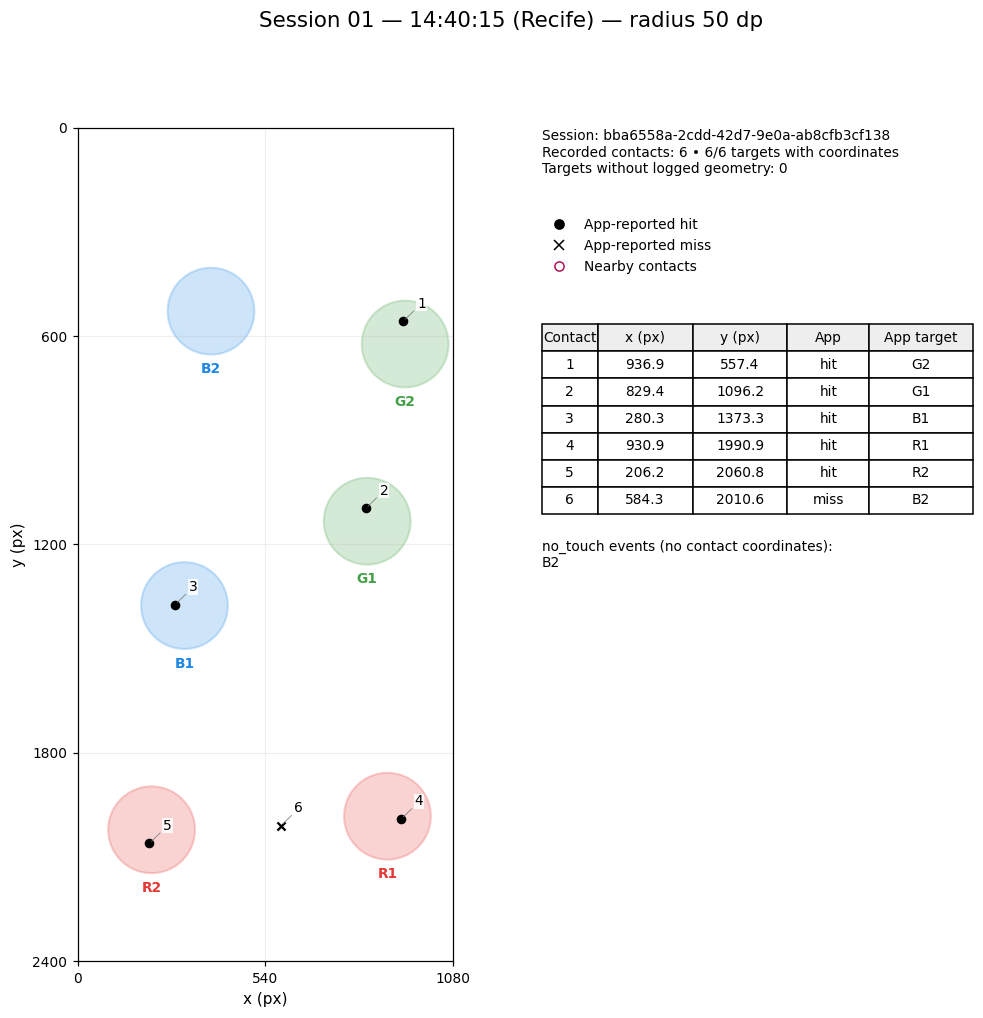

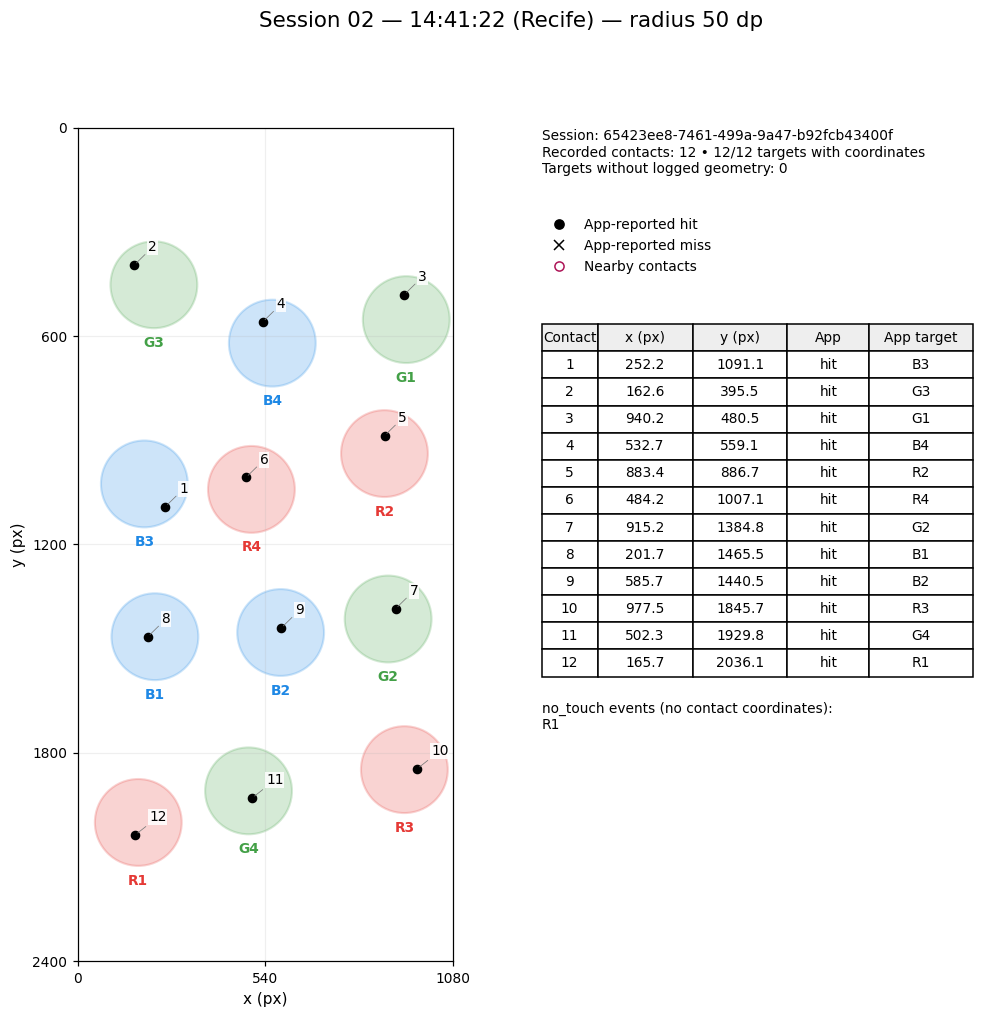

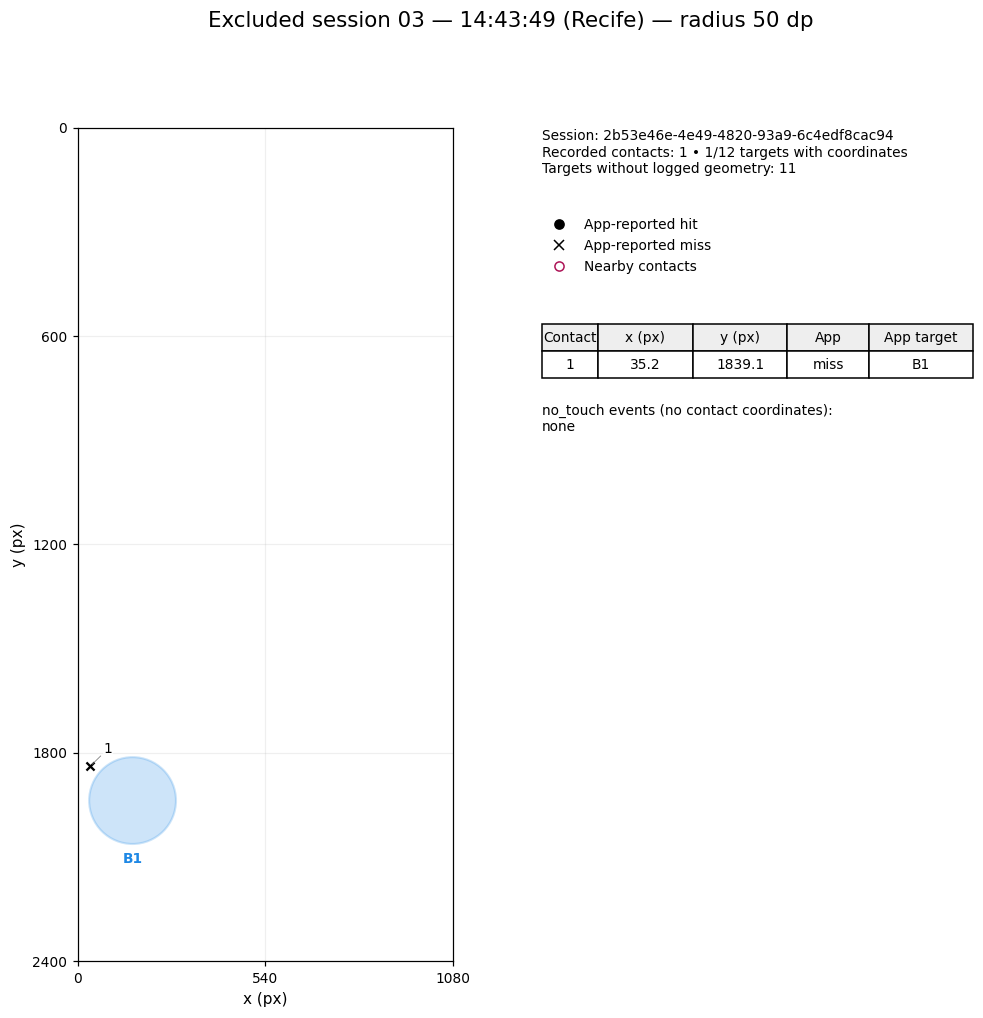

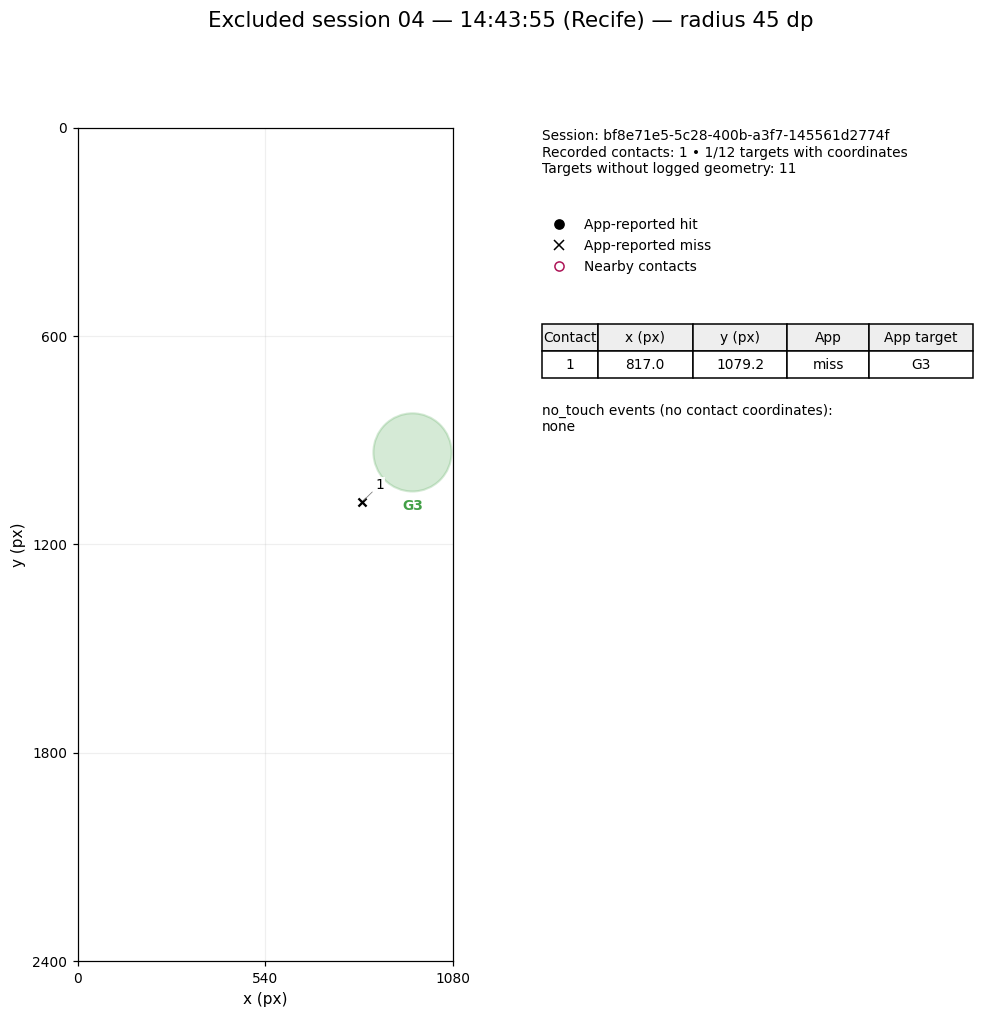

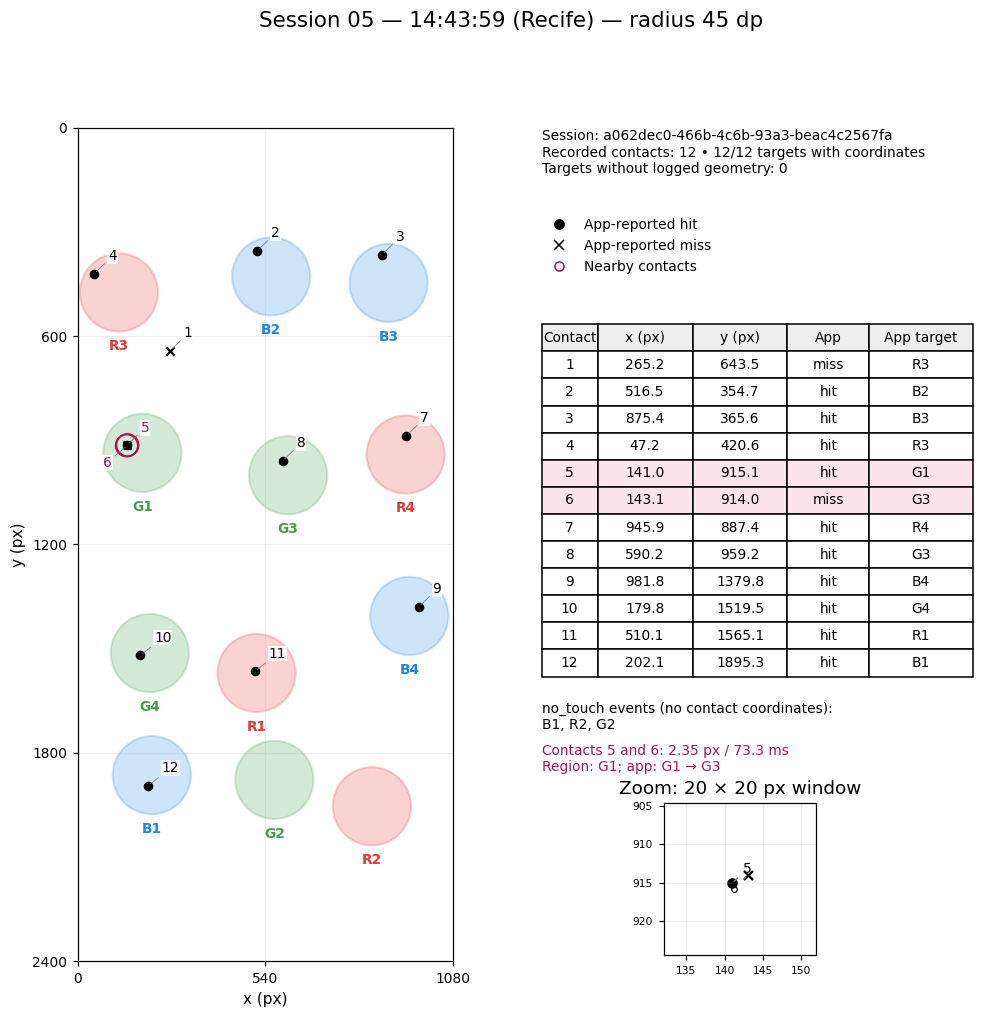

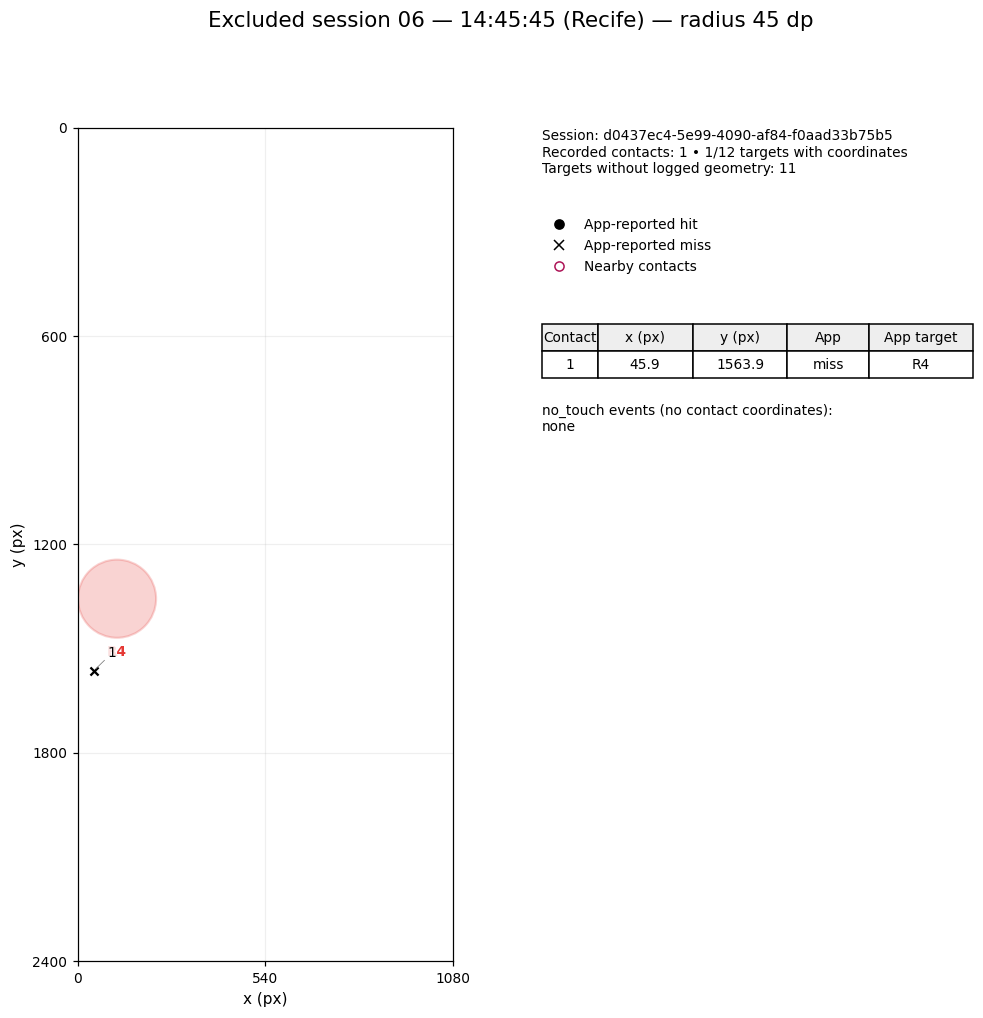

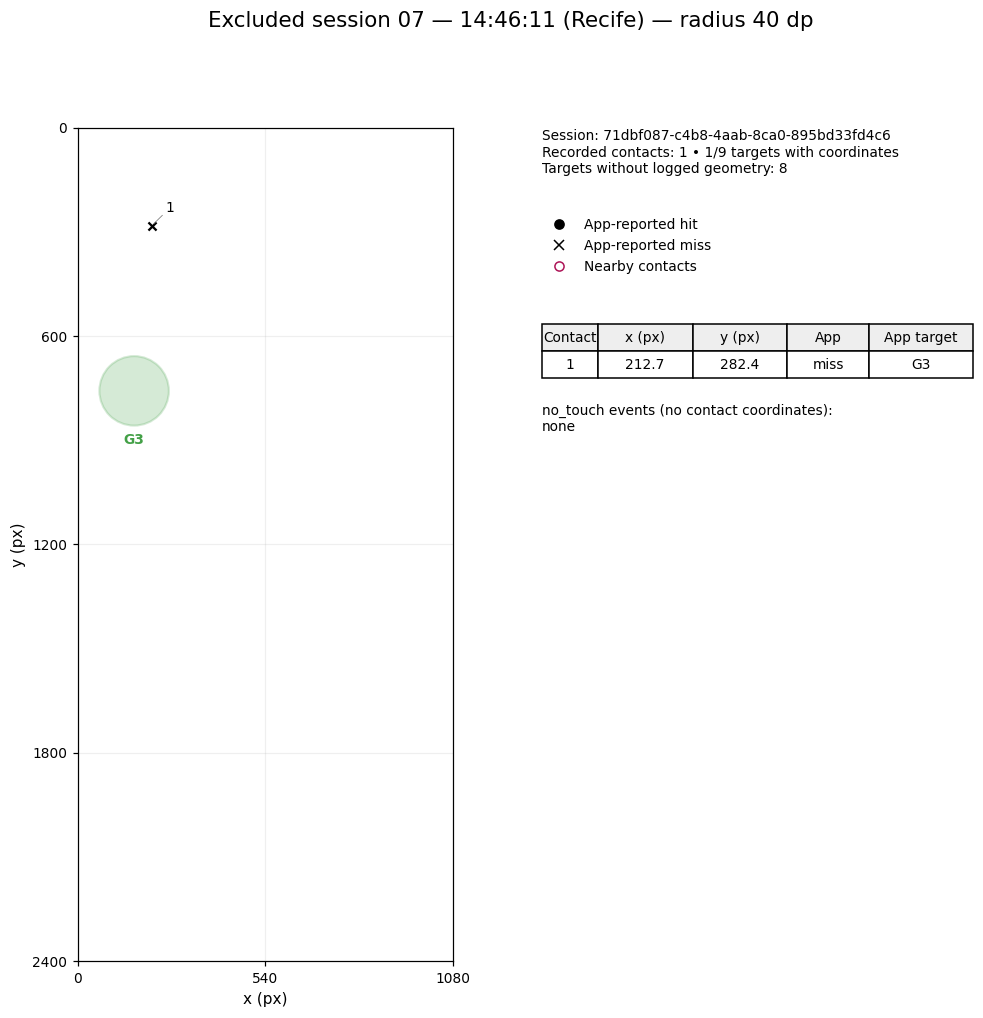

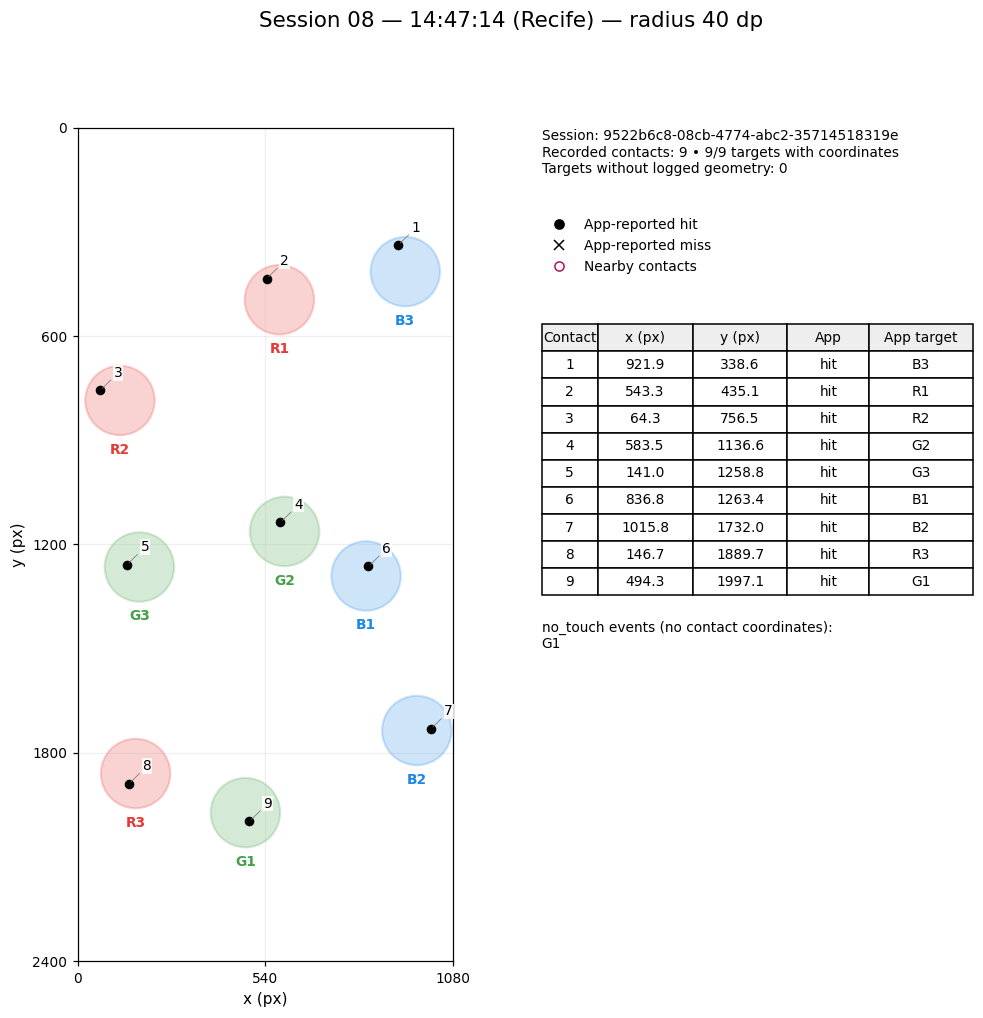

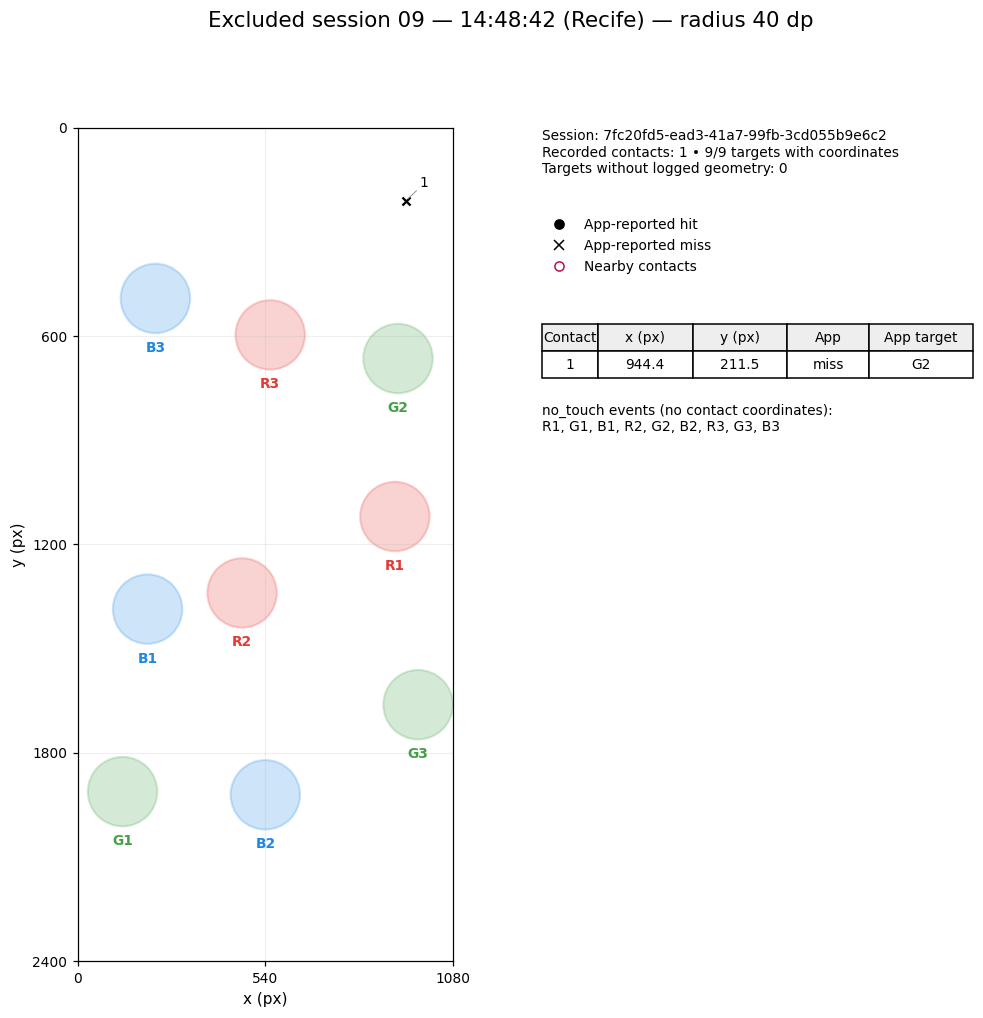

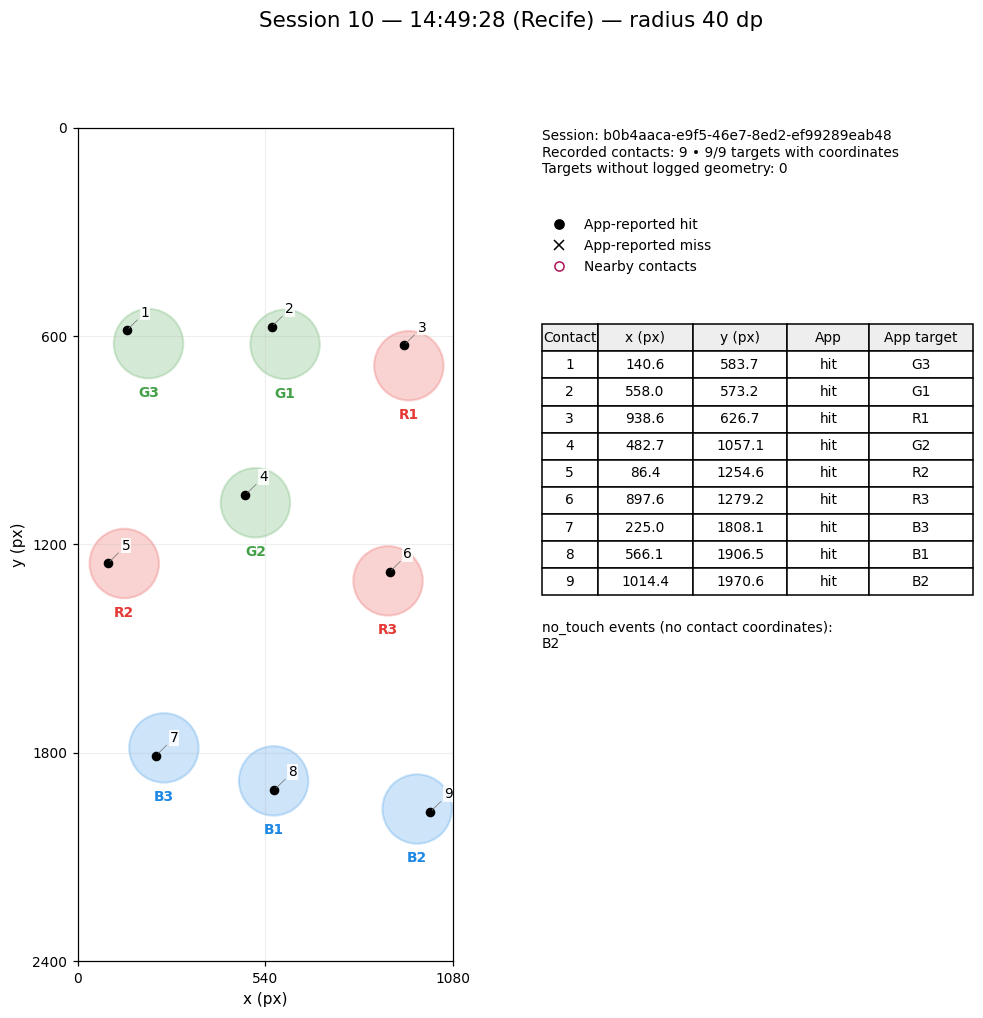

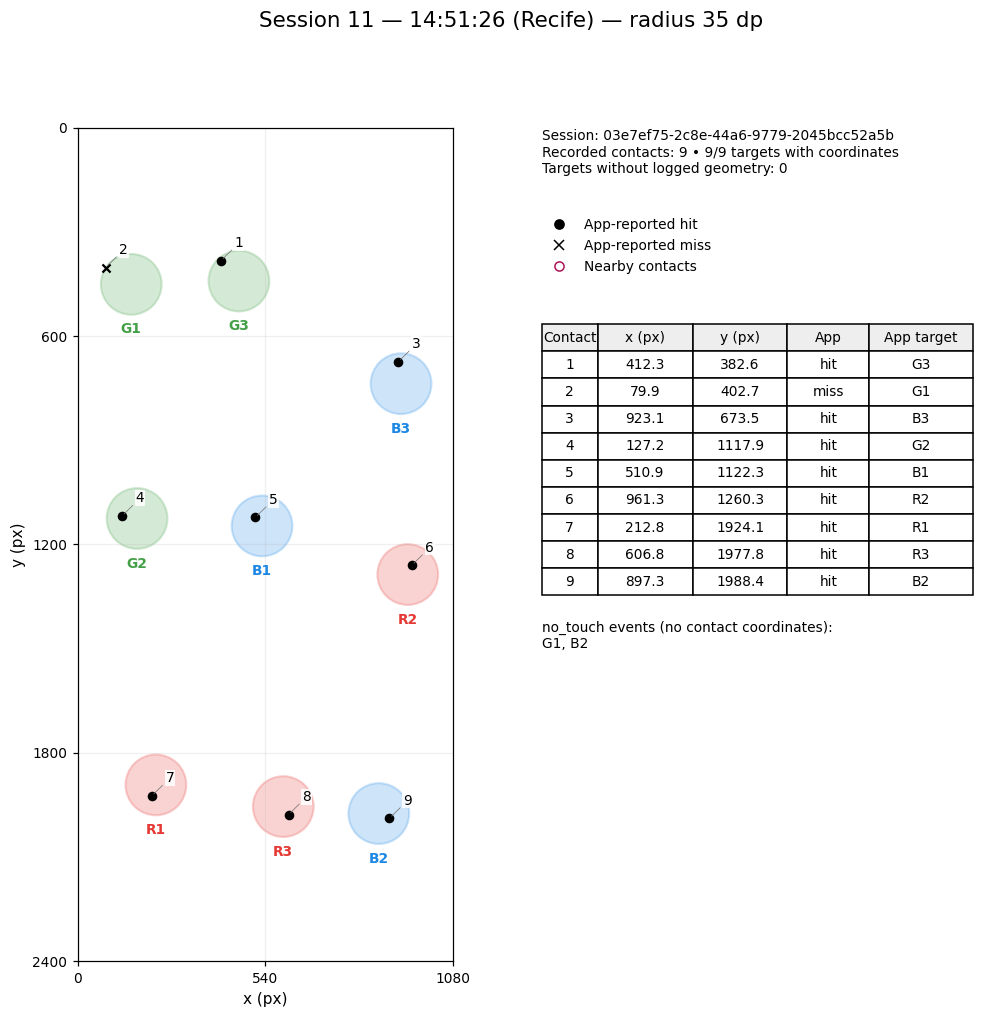

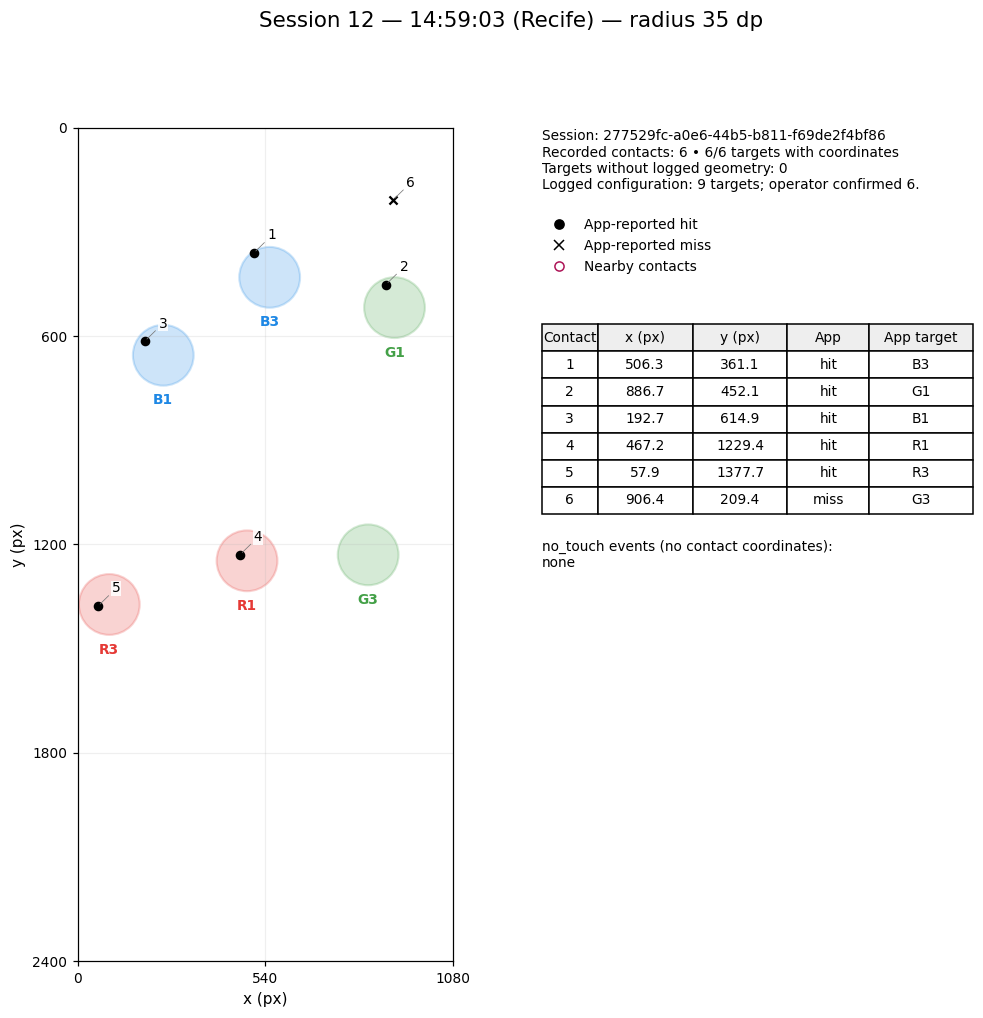

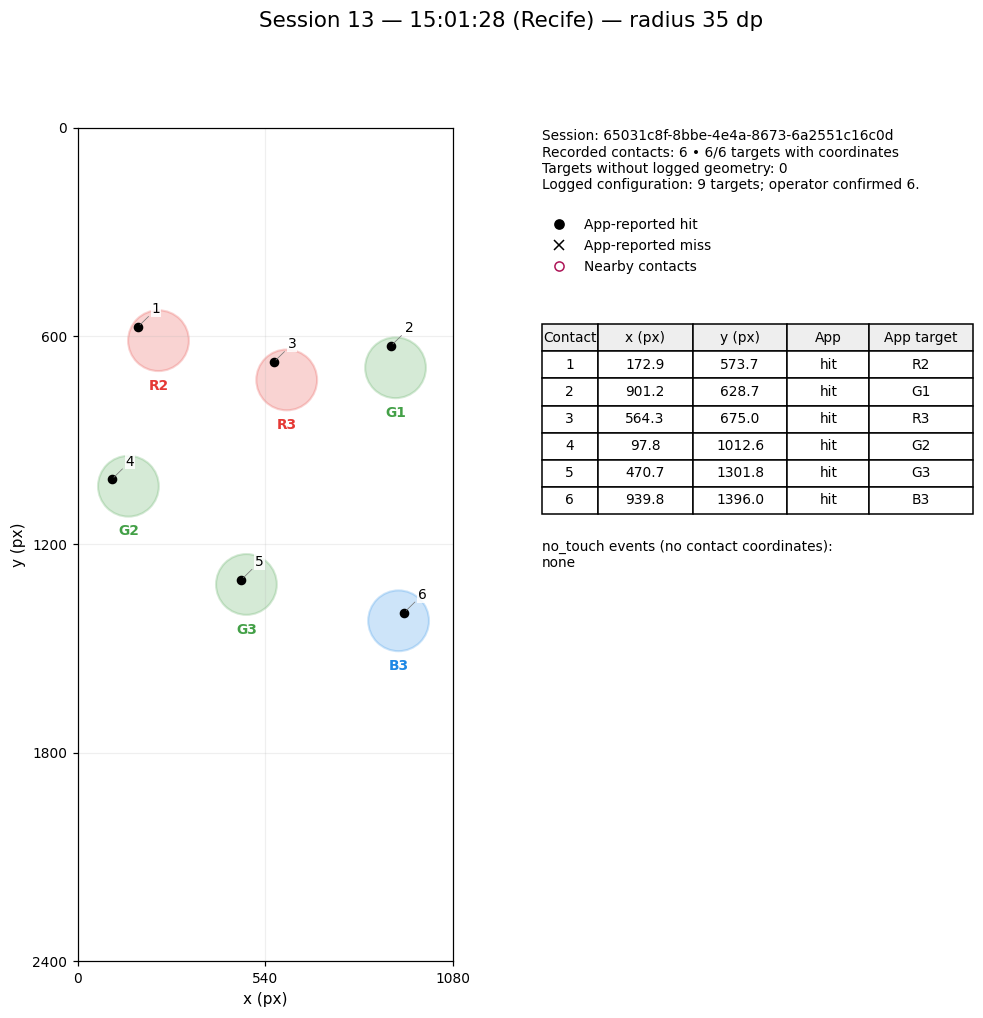

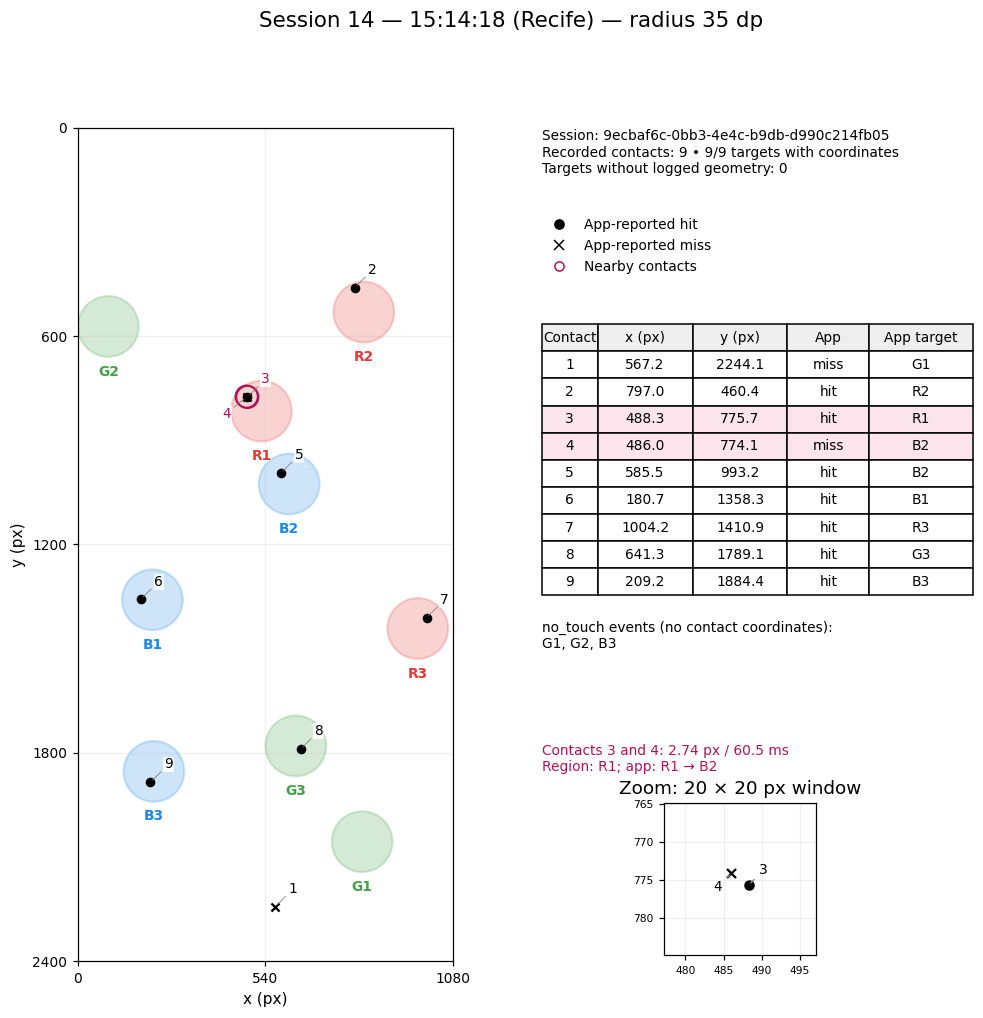

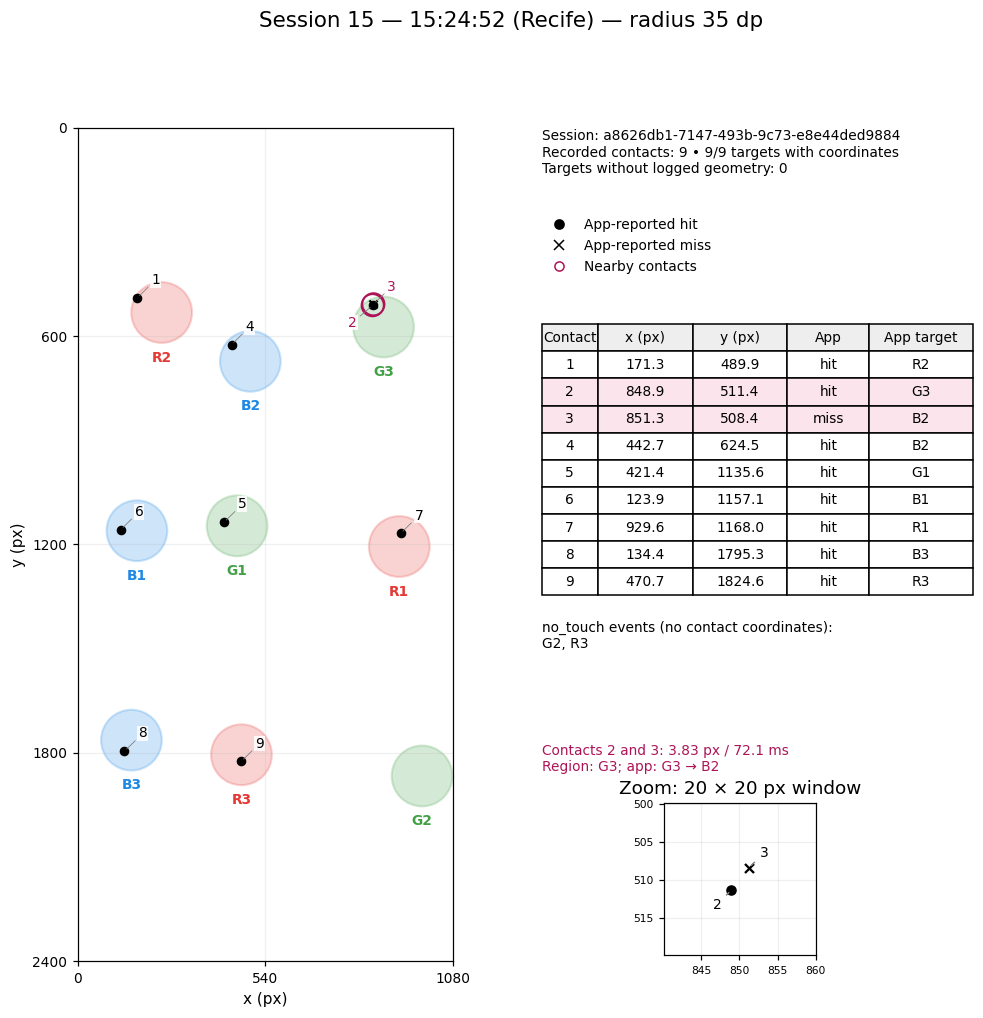

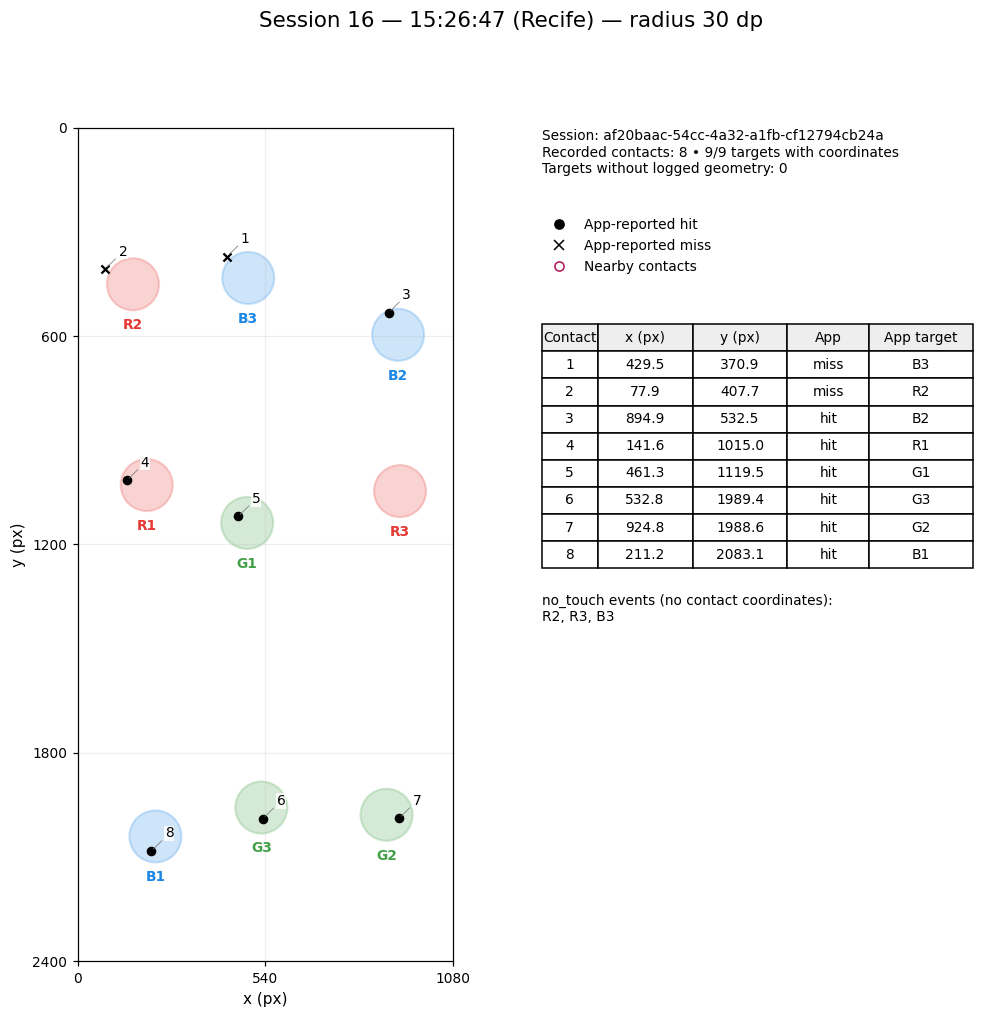

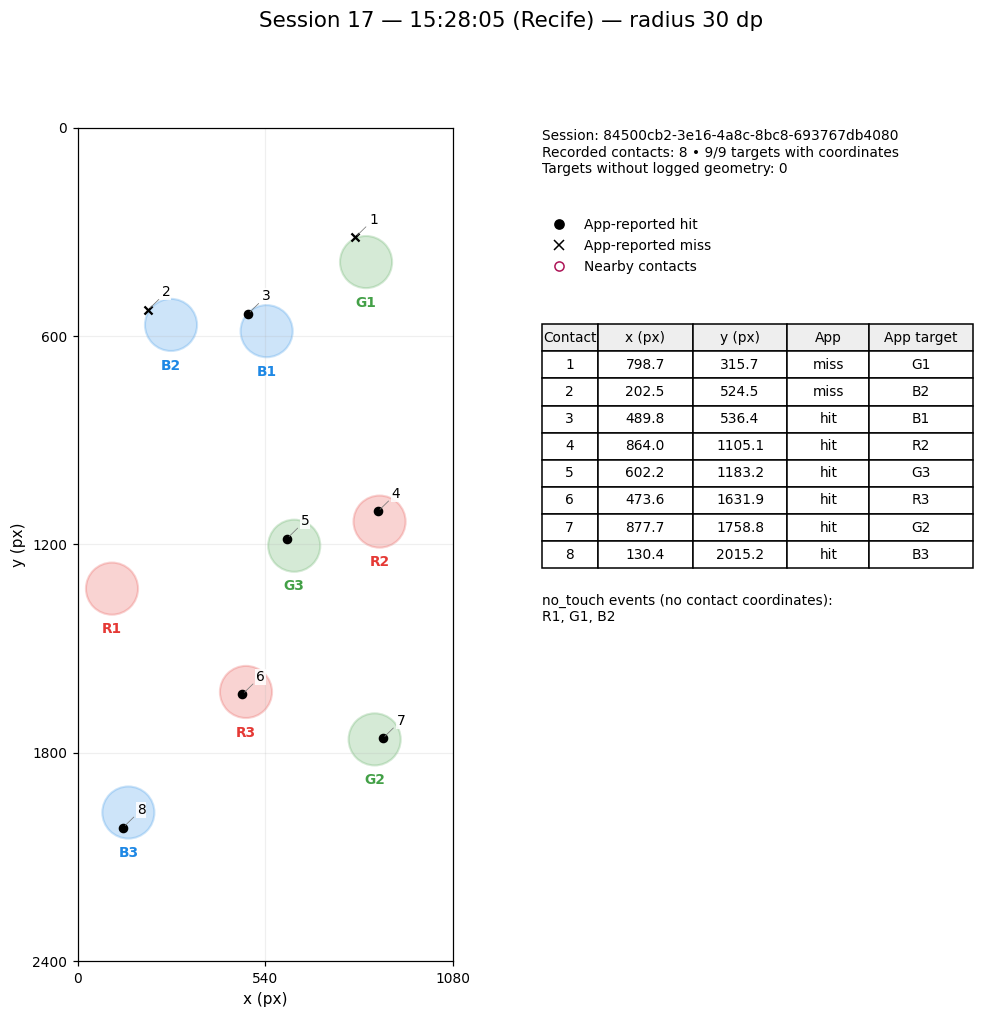

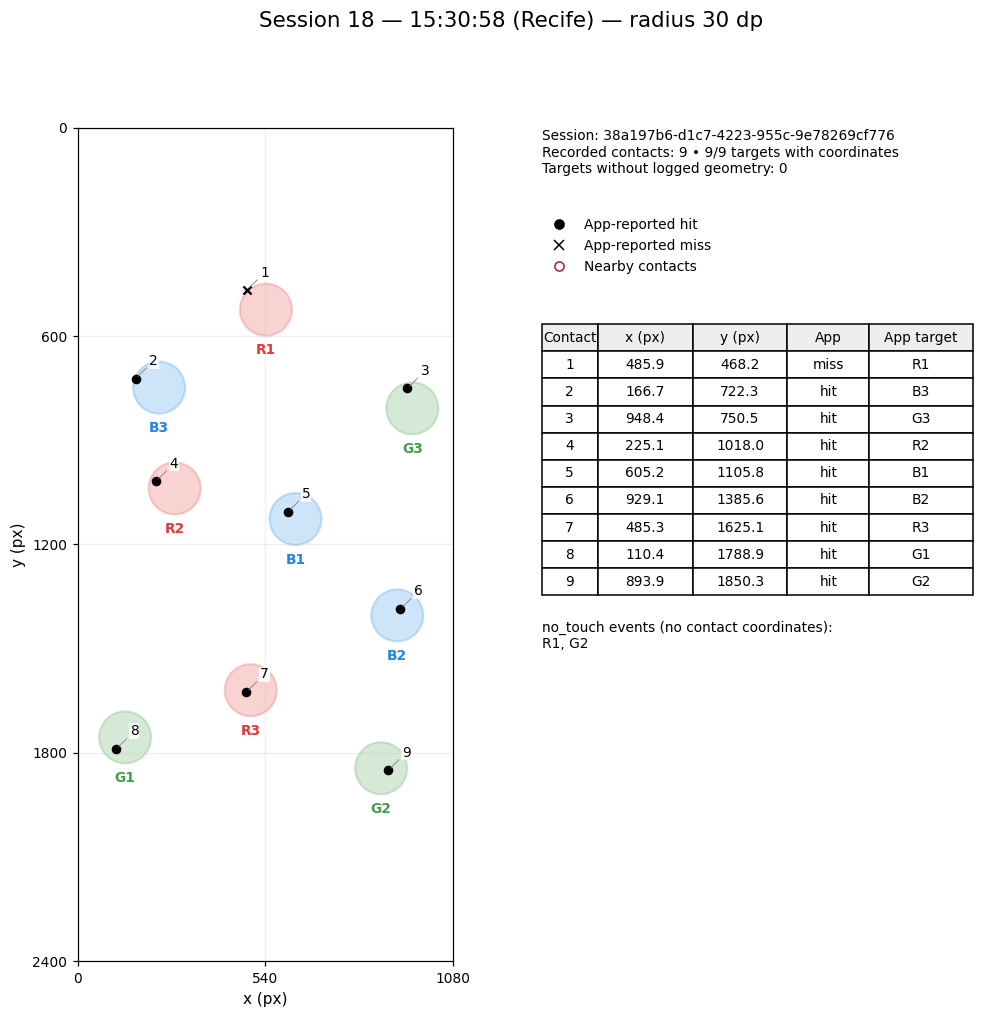

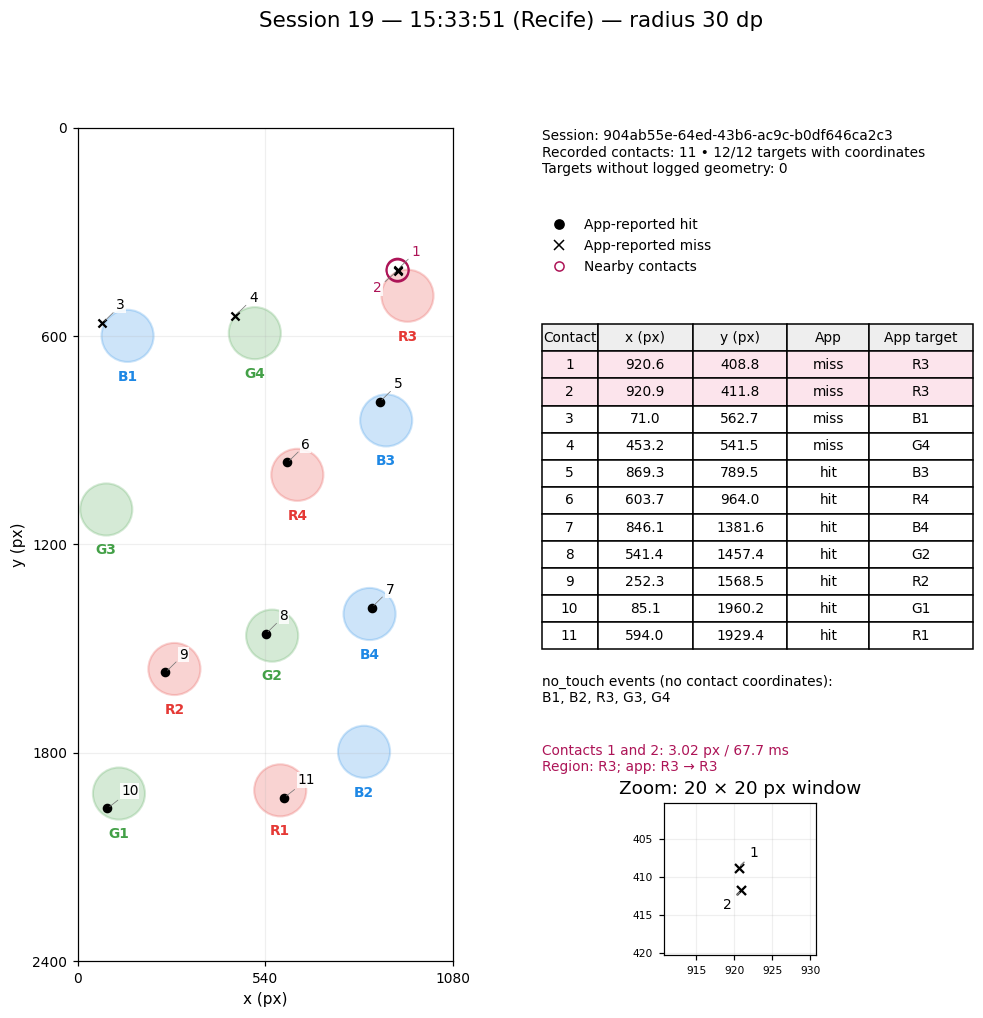

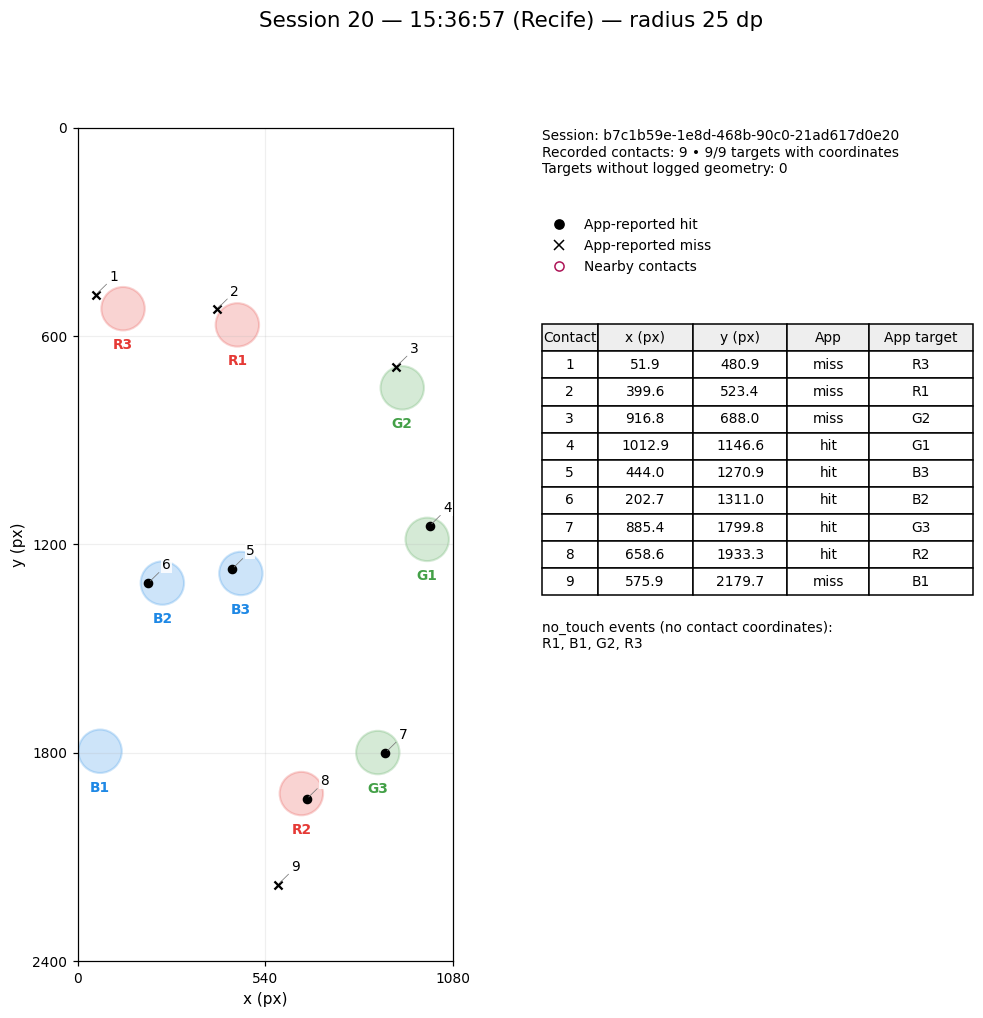

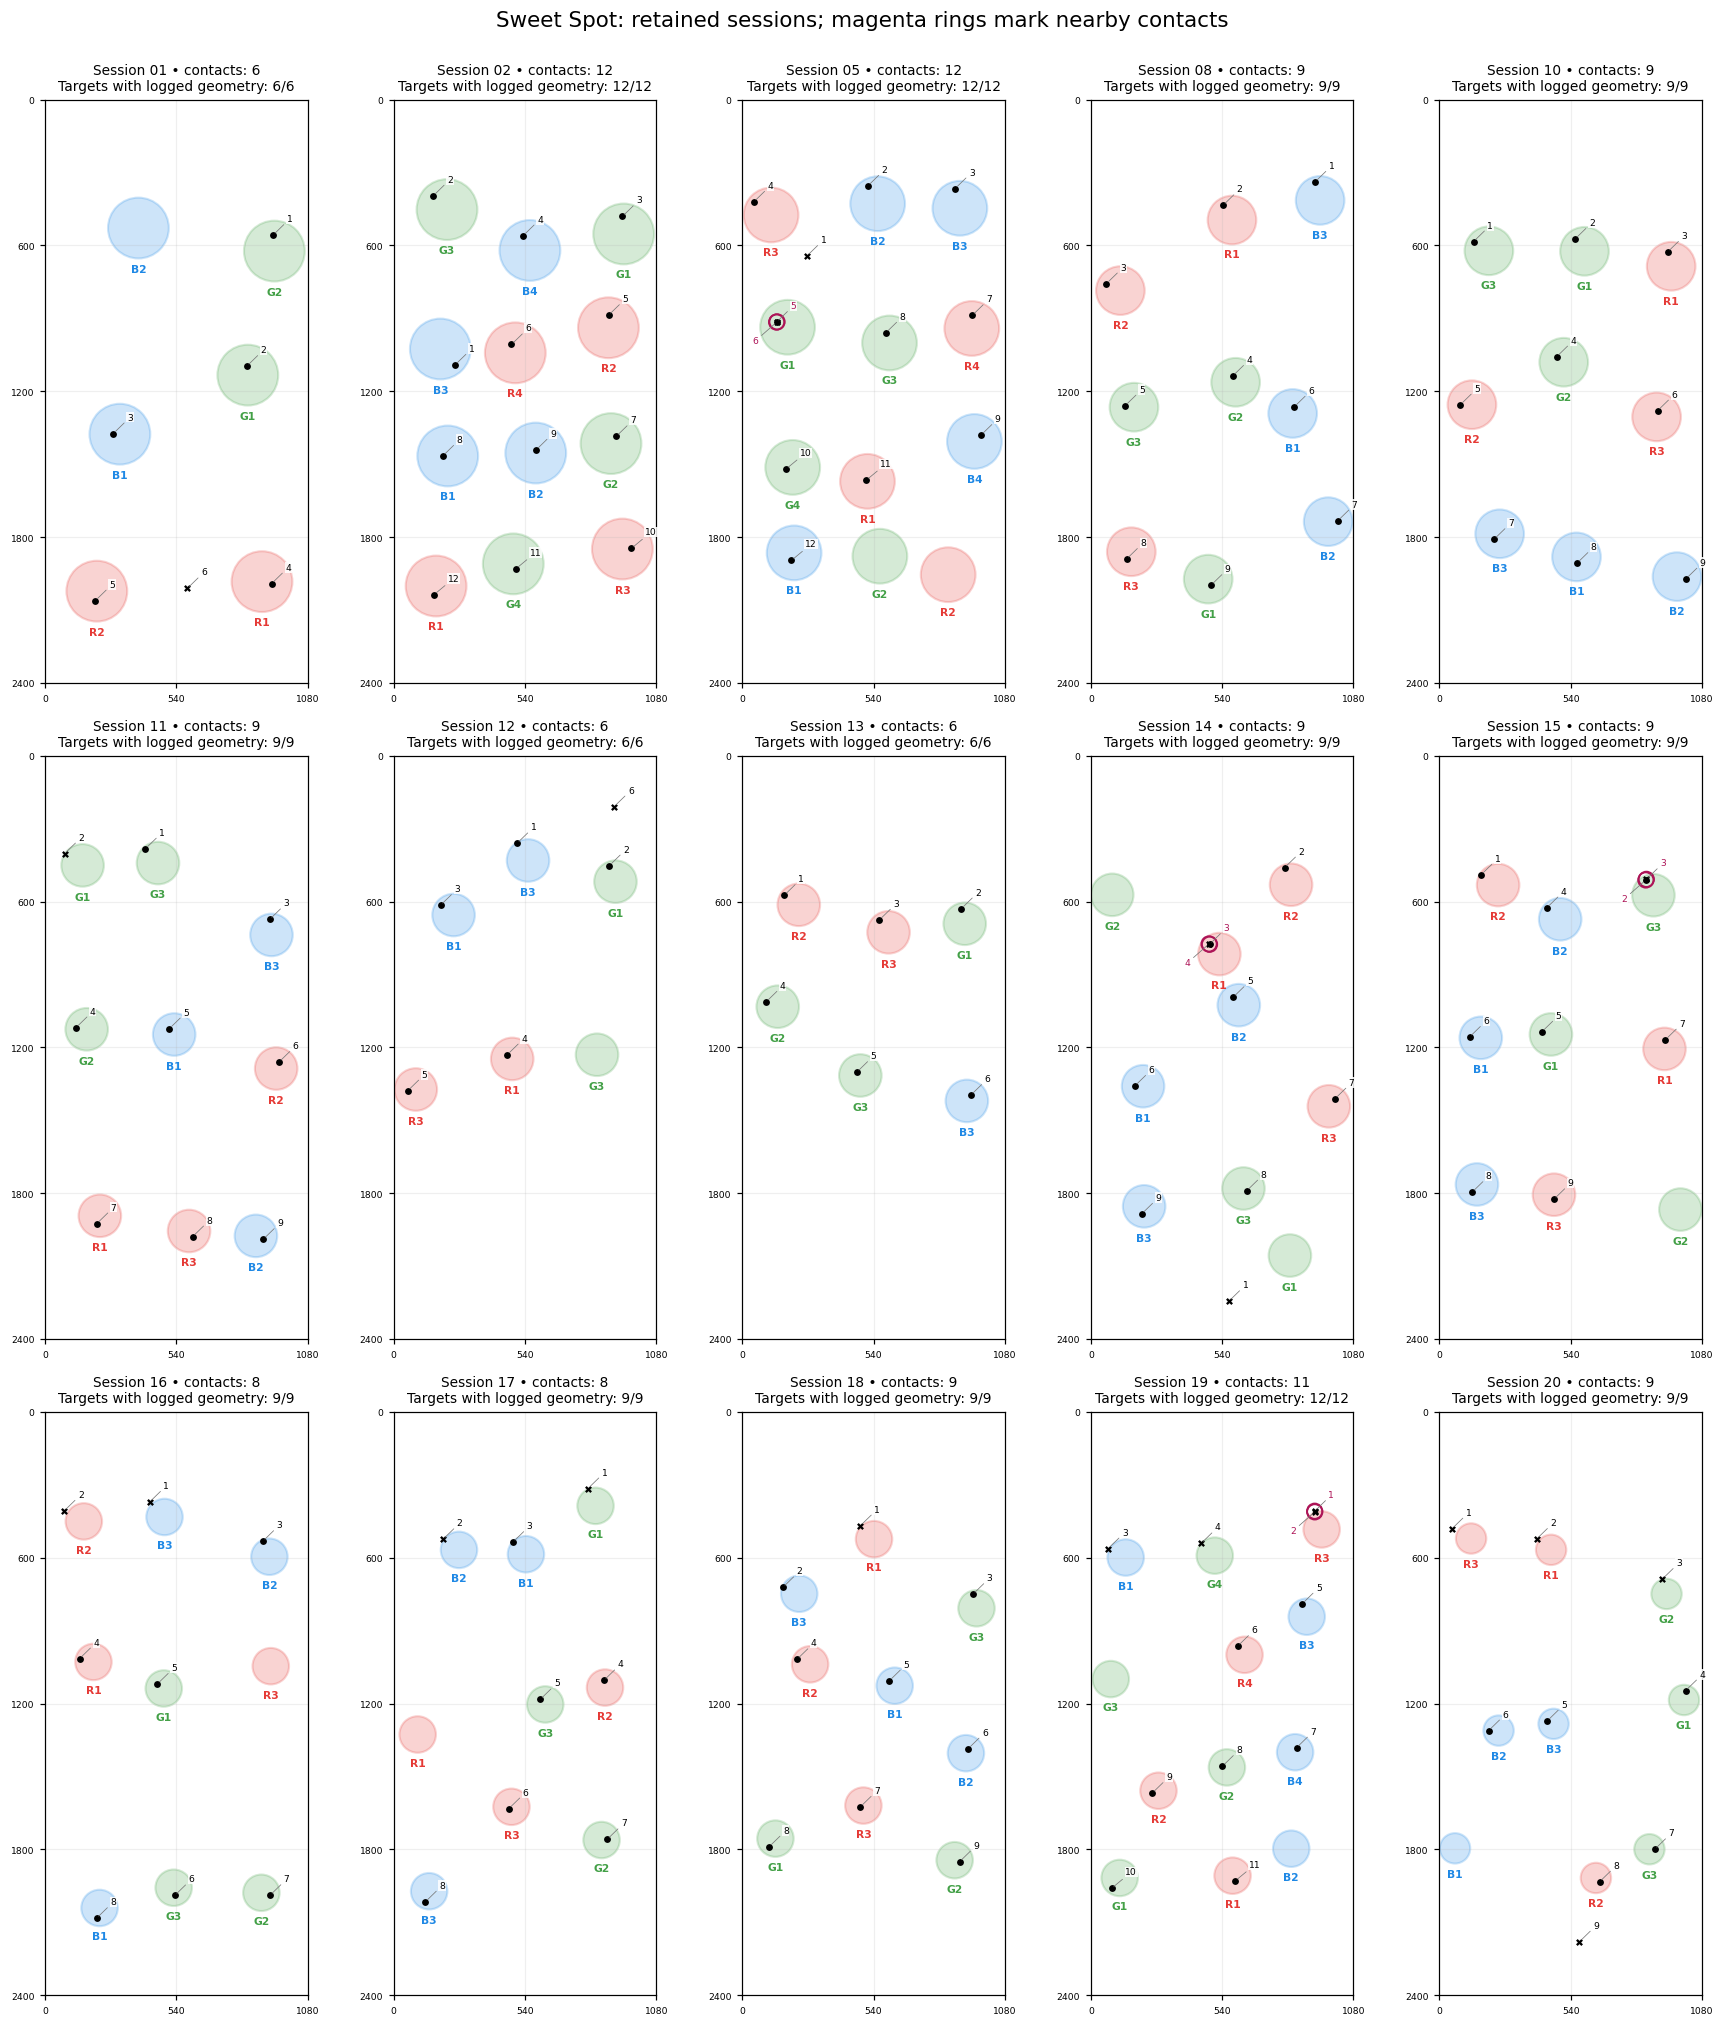

15 PNG maps and PDF with 15 pages exported.


In [10]:
from matplotlib.patches import Circle
from matplotlib.lines import Line2D
from matplotlib.backends.backend_pdf import PdfPages

MAPS = OUTPUT / 'session_maps'
MAPS.mkdir(exist_ok=True)
(OUTPUT / 'excluded_sessions/maps').mkdir(exist_ok=True)
TARGET_COLORS = {'red': '#e53935', 'green': '#43a047', 'blue': '#1e88e5'}

def short_target_name(tid):
    _, trio, color = tid.split('-')
    return {'red': 'R', 'green': 'G', 'blue': 'B'}[color] + str(int(trio))

def draw_screen(ax, rs, pairs, compact=False):
    ts = [r for r in rs if r['actual_touch_x'] is not None]
    geo = {r['target_id']: r for r in rs}
    marked_indices = {p[k] for p in pairs for k in ('touch_a', 'touch_b')}
    for tid, r in geo.items():
        color = TARGET_COLORS[tid.rsplit('-', 1)[-1]]
        ax.add_patch(Circle((r['target_center_x'], r['target_center_y']), r['target_radius'],
                            facecolor=color, edgecolor=color, alpha=.22, linewidth=1.4))
        ax.text(r['target_center_x'], r['target_center_y'] + r['target_radius'] + 22,
                short_target_name(tid), ha='center', va='top', color=color, fontsize=7 if compact else 9, weight='bold')
    for j, r in enumerate(ts, 1):
        x, y = r['actual_touch_x'], r['actual_touch_y']
        ax.scatter(x, y, marker='o' if r['result'] == 'hit' else 'x', color='black', s=12 if compact else 28, zorder=4)
        if j in marked_indices:
            ax.scatter(x, y, s=100 if compact else 210, facecolors='none', edgecolors='#ad1457', linewidths=1.2, zorder=5)
        offset = (9, 9) if j not in marked_indices or j % 2 else (-16, -14)
        ax.annotate(str(j), (x, y), xytext=offset, textcoords='offset points',
                    fontsize=6 if compact else 9, color='#ad1457' if j in marked_indices else 'black',
                    bbox=dict(facecolor='white', edgecolor='none', alpha=.85, pad=.5),
                    arrowprops=dict(arrowstyle='-', color='#777777', linewidth=.5), zorder=6)
    ax.set(xlim=(0, rs[0]['screen_width']), ylim=(rs[0]['screen_height'], 0), aspect='equal')
    ax.set_xticks([0, 540, 1080])
    ax.set_yticks([0, 600, 1200, 1800, 2400])
    ax.tick_params(labelsize=6 if compact else 9)
    if not compact:
        ax.set(xlabel='x (px)', ylabel='y (px)')
    return ts, geo

legend = [Line2D([0], [0], marker='o', color='black', linestyle='none', label='App-reported hit'),
           Line2D([0], [0], marker='x', color='black', linestyle='none', label='App-reported miss'),
           Line2D([0], [0], marker='o', markerfacecolor='none', markeredgecolor='#ad1457', linestyle='none', label='Nearby contacts')]

with PdfPages(OUTPUT / 'all_session_maps.pdf') as pdf:
    for sid in original_order:
        rs = original_groups[sid]
        number = session_number[sid]
        pairs = [p for p in touch_pairs if p['session_number'] == number and p['nearby']]
        fig = plt.figure(figsize=(10.5, 10))
        gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.15], wspace=.22)
        ax = fig.add_subplot(gs[0, 0])
        info = fig.add_subplot(gs[0, 1])
        info.axis('off')
        ts, geo = draw_screen(ax, rs, pairs)
        config = rs[0]['configuration']
        time_label = rs[0]['timestamp'].astimezone(LOCAL_TIMEZONE).strftime('%H:%M:%S')
        label = "Excluded session" if number in EXCLUDED_SESSION_NUMBERS else "Session"
        fig.suptitle(f"{label} {number:02d} — {time_label} (Recife) — radius {rs[0]['target_radius_dp']:g} dp", fontsize=14)
        n = len(expected_target_ids(sid))
        missing_count = n - len(geo)
        config_note = f"\nLogged configuration: {config['target_count']} targets; operator confirmed {n}." if number in OPERATOR_TARGET_COUNTS else ''
        info.text(0, .99, f"Session: {sid}\nRecorded contacts: {len(ts)} • {len(geo)}/{n} targets with coordinates\nTargets without logged geometry: {missing_count}{config_note}",
                  transform=info.transAxes, va='top', fontsize=9)
        info.legend(handles=legend, loc='upper left', bbox_to_anchor=(-.02, .9), frameon=False, fontsize=9)
        table_data = [[j, f"{r['actual_touch_x']:.1f}", f"{r['actual_touch_y']:.1f}", r['result'], short_target_name(r['target_id'])] for j, r in enumerate(ts, 1)]
        height = .032 * (len(table_data) + 1)
        tbl = info.table(cellText=table_data, colLabels=['Contact', 'x (px)', 'y (px)', 'App', 'App target'],
                         colWidths=[.13, .22, .22, .19, .24], bbox=[0, .76 - height, 1, height], cellLoc='center')
        tbl.auto_set_font_size(False)
        tbl.set_fontsize(9)
        for key, cell in tbl.get_celld().items():
            if key[0] == 0:
                cell.set_facecolor('#eeeeee')
            if key[0] in {p[k] for p in pairs for k in ('touch_a', 'touch_b')}:
                cell.set_facecolor('#fce4ec')
        manual = [short_target_name(r['target_id']) for r in rs if r['result'] == 'no_touch']
        info.text(0, .73 - height, 'no_touch events (no contact coordinates):\n' + (', '.join(manual) if manual else 'none'),
                  transform=info.transAxes, va='top', fontsize=9, wrap=True)
        for k, pair in enumerate(pairs):
            info.text(0, .265 - k * .30, f"Contacts {pair['touch_a']} and {pair['touch_b']}: {pair['distance_px']:.2f} px / {pair['interval_ms']:.1f} ms\n"
                      f"Region: {short_target_name(pair['shared_nearest_target_id']) if pair['shared_nearest_target_id'] else 'no shared nearby target'}; app: {short_target_name(pair['assigned_target_a'])} → {short_target_name(pair['assigned_target_b'])}",
                      transform=info.transAxes, va='top', fontsize=9, color='#ad1457')
            zoom = info.inset_axes([.12, .015 - k * .30, .68, .18])
            mid_x = (pair['x_a'] + pair['x_b']) / 2
            mid_y = (pair['y_a'] + pair['y_b']) / 2
            for j in (pair['touch_a'], pair['touch_b']):
                r = ts[j - 1]
                zoom.scatter(r['actual_touch_x'], r['actual_touch_y'], marker='o' if r['result'] == 'hit' else 'x', color='black', s=35)
                zoom.annotate(str(j), (r['actual_touch_x'], r['actual_touch_y']), xytext=(7, 7) if j % 2 else (-12, -12), textcoords='offset points', fontsize=9, arrowprops=dict(arrowstyle='-', color='gray'))
            zoom.set(xlim=(mid_x - 10, mid_x + 10), ylim=(mid_y + 10, mid_y - 10), aspect='equal', title='Zoom: 20 × 20 px window')
            zoom.tick_params(labelsize=7)
        if number not in EXCLUDED_SESSION_NUMBERS:
            pdf.savefig(fig, bbox_inches='tight')
        folder = 'excluded_sessions/maps' if number in EXCLUDED_SESSION_NUMBERS else 'session_maps'
        save_figure(f'{folder}/session_{number:02d}.png', fig)

panel_rows = math.ceil(len(session_order) / 5)
fig, axs = plt.subplots(panel_rows, 5, figsize=(16, 6.25 * panel_rows), squeeze=False)
for ax, sid in zip(axs.flat, session_order):
    number = session_number[sid]
    rs = groups[sid]
    pairs = [p for p in touch_pairs if p['session_number'] == number and p['nearby']]
    ts, geo = draw_screen(ax, rs, pairs, compact=True)
    ax.set_title(f"Session {number:02d} • contacts: {len(ts)}\nTargets with logged geometry: {len(geo)}/{len(expected_target_ids(sid))}", fontsize=9)
for ax in axs.flat[len(session_order):]:
    ax.set_visible(False)
fig.suptitle('Sweet Spot: retained sessions; magenta rings mark nearby contacts', fontsize=14)
fig.tight_layout(rect=(0, 0, 1, .98))
save_figure('05_session_overview.png', fig)
assert len(list(MAPS.glob('session_*.png'))) == len(sessions)
print(f"{len(sessions)} PNG maps and PDF with {len(sessions)} pages exported.")

### Minimal executable check for spatial classification

Synthetic contacts check that a manual row does not create a contact, different app target IDs do not hide a spatial repeat, and a distant contact is treated according to the configured threshold.
Data reconciliation checks use the same functions as the analysis.

In [11]:
def check_pair_detection():
    base = dict(groups[session_order[0]][0])
    a = dict(base, target_id='trio-001-red', target_center_x=100, target_center_y=100,
             actual_touch_x=100, actual_touch_y=100, result='hit')
    b = dict(base, target_id='trio-001-blue', target_center_x=500, target_center_y=500,
             actual_touch_x=103, actual_touch_y=100, result='miss',
             timestamp=a['timestamp'] + timedelta(milliseconds=70))
    manual = dict(a, actual_touch_x=None, actual_touch_y=None, result='no_touch')
    c = dict(b, actual_touch_x=500, actual_touch_y=500,
             timestamp=a['timestamp'] + timedelta(seconds=2))
    pp = detect_pairs([a, manual, b, c])
    assert len(pp) == 3  # Three pairs from three contacts; manual events excluded.
    assert pp[0]['distance_px'] == 3 and math.isclose(pp[0]['interval_ms'], 70)
    assert pp[0]['rapid_repeated_contact_candidate'] == (3 <= NEARBY_DISTANCE_DP * base['target_radius'] / base['target_radius_dp'] and 70 <= RAPID_CONTACT_WINDOW_MS)
    assert pp[0]['same_target_region']
    assert pp[0]['assigned_target_a'] != pp[0]['assigned_target_b']
    assert all(p['nearby'] == (p['distance_px'] <= NEARBY_DISTANCE_DP * base['target_radius'] / base['target_radius_dp']) for p in pp)
    assert len(touch_pairs) == sum(math.comb(s['touches'], 2) for s in sessions)
    print('Spatial check passed; different target IDs do not hide repeated coordinates.')
check_pair_detection()

repeated_contact_report = '# Repeated contacts: Sweet Spot\n\n'
repeated_contact_report += f'{len(nearby_pairs)} nearby pairs in {len({p["session_number"] for p in nearby_pairs})} retained sessions; {len(rapid_pairs)} rapid-repeat candidates.\n\n'
repeated_contact_report += '| Session | Contacts | Distance (px) | Interval (ms) | Nearest target | App outcomes |\n|---|---|---:|---:|---|---|\n'
for pair in nearby_pairs:
    repeated_contact_report += f"| {pair['session_number']} | {pair['touch_a']} and {pair['touch_b']} | {pair['distance_px']:.2f} | {pair['interval_ms']:.1f} | {pair['shared_nearest_target_id']} | {pair['result_a']} → {pair['result_b']} |\n"
repeated_contact_report += '\nIn sessions 5, 14, and 15, the second contact was attributed to a different target although the positions nearly coincide. In session 19, both contacts lie just outside the same circle.\n\n'
repeated_contact_report += 'These are recorded-contact observations, consistent with repeated contact; physical cause is unverified. App outcomes remain unmodified.\n'
(OUTPUT / 'repeated_contacts.md').write_text(repeated_contact_report, encoding='utf-8')

Spatial check passed; different target IDs do not hide repeated coordinates.


780

## 9. Screen distribution, application timing, and IMU

Spatial distributions are exploratory because target placement was not balanced across trials.
`response_time_ms` is an application timer and may include setup, waiting, and operator intervention; it is not robot motion duration or input latency.
The interval between first and last event omits preparation before the first event.

The IMU provides one sample per event, not a continuous motion or impact trace. Euler angles near ±90° pitch can be unstable; yaw/roll changes are not interpreted as equivalent support motion.
Gyroscope magnitudes are descriptive and do not establish a cause of contact failure or repetition.

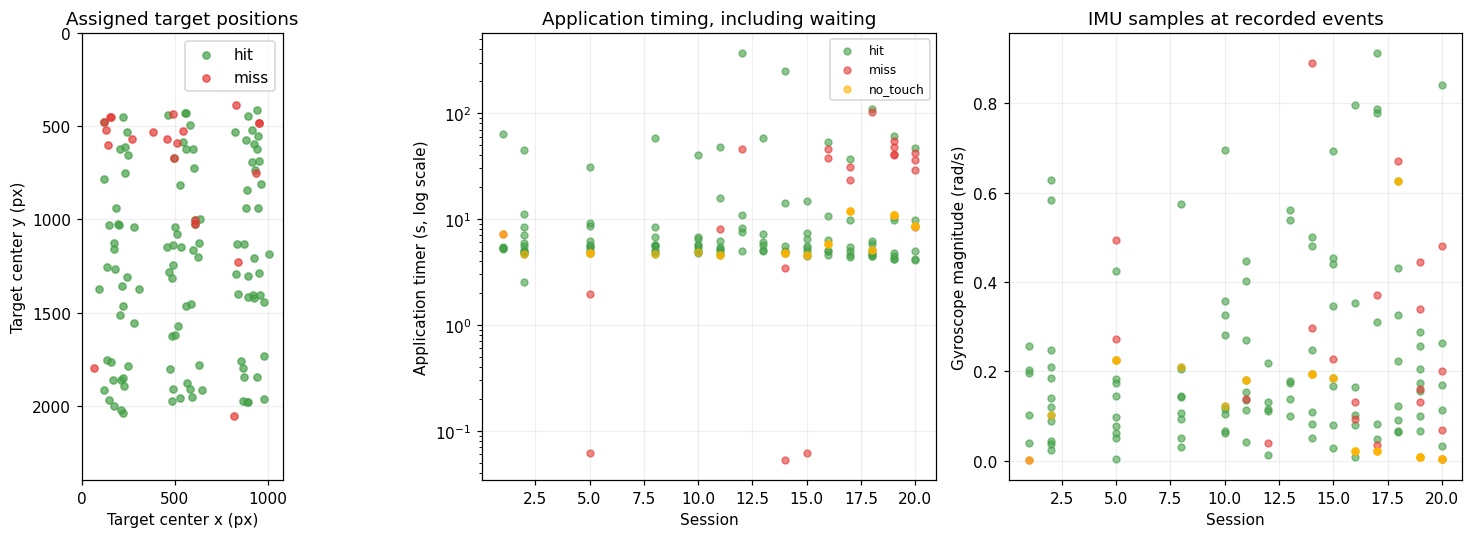

sample,n,median_s,p90_s,maximum_s
All recorded contacts,132,5.622,45.643,365.768
Contacts after the first in each session,117,5.521,38.406,249.409
Manual no_touch events,31,5.813,10.979,11.946


IMU present in 163 of 163 events.


In [12]:
fig, axs = plt.subplots(1, 3, figsize=(14, 5))
for status, color in [('hit', '#43a047'), ('miss', '#e53935')]:
    ee = [e for e in et if e['result'] == status]
    axs[0].scatter([e['target_x'] for e in ee], [e['target_y'] for e in ee], color=color, label=status, s=22, alpha=.7)
axs[0].set(xlim=(0, 1080), ylim=(2400, 0), xlabel='Target center x (px)', ylabel='Target center y (px)', title='Assigned target positions')
axs[0].set_aspect('equal')
axs[0].legend()
for status, color in [('hit', '#43a047'), ('miss', '#e53935'), ('no_touch', '#ffb300')]:
    ee = [e for e in events if e['result'] == status]
    axs[1].scatter([e['session_number'] for e in ee], [e['app_response_s'] for e in ee], color=color, label=status, s=20, alpha=.6)
axs[1].set(yscale='log', xlabel='Session', ylabel='Application timer (s, log scale)', title='Application timing, including waiting')
axs[1].legend(fontsize=8)
imu = [r for r in records if r.get('imu')]
for status, color in [('hit', '#43a047'), ('miss', '#e53935'), ('no_touch', '#ffb300')]:
    rr = [r for r in imu if r['result'] == status]
    axs[2].scatter([session_number[r['session_id']] for r in rr], [math.sqrt(sum(v*v for v in r['imu']['gyroscope_rad_s'])) for r in rr], color=color, label=status, s=20, alpha=.6)
axs[2].set(xlabel='Session', ylabel='Gyroscope magnitude (rad/s)', title='IMU samples at recorded events')
fig.tight_layout()
save_figure('04_screen_time_imu.png', fig)

time_summary = []
for name, ee in [('All recorded contacts', et), ('Contacts after the first in each session', [e for e in et if e['touch_index'] > 1]), ('Manual no_touch events', [e for e in events if e['result'] == 'no_touch'])]:
    values = [e['app_response_s'] for e in ee]
    time_summary.append(dict(sample=name, n=len(values), median_s=round(float(np.median(values)), 3),
                      p90_s=round(float(np.percentile(values, 90)), 3), maximum_s=max(values)))
show_table(time_summary)
print('IMU present in', len(imu), 'of', len(records), 'events.')


## 10. Reconciliation checks

Check event partitioning, per-session/per-target denominators, and the documented six-target corrections.
Synthetic examples ensure that N+1 event rows with only N contacts cannot demonstrate removal of a contact ceiling.
The tests check the processing rules, not the physical truth of operator annotations.

In [13]:
def check_classification():
    # Check processing rules with synthetic data, independently of the measured totals.
    n = 2
    before = [dict(actual_touch_x=1, result='hit', target_id='a'),
             dict(actual_touch_x=2, result='miss', target_id='b'),
             dict(actual_touch_x=None, result='no_touch', target_id='b')]
    nt = sum(r['actual_touch_x'] is not None for r in before)
    assert len(before) > n and nt == n and not (nt > n)
    after = before + [dict(actual_touch_x=3, result='hit', target_id='b')]
    assert sum(r['actual_touch_x'] is not None for r in after) > n
    assert n - len({r['target_id'] for r in before[:1]}) == 1
    assert n - len({r['target_id'] for r in before}) == 0
    assert len(events) == len(records)
    assert sum(s['touches'] + s['no_touch'] for s in sessions) == len(records)
    assert len(targets) == sum(s['effective_target_count'] for s in sessions)
    assert all(s['recorded_target_count'] + s['targets_without_records'] == s['effective_target_count'] for s in sessions)
    assert sum(s['targets_with_hit'] + s['targets_with_miss_without_hit'] + s['targets_with_no_touch_only'] + s['targets_without_records'] for s in sessions) == len(targets)
    assert sum(a['status'] == 'hit' for a in targets) == sum(s['targets_with_hit'] for s in sessions)
    assert all(not s['missing_target_records'] and s['effective_target_count'] == 6 and s['logged_target_count'] == 9
               for s in sessions if s['session_number'] in OPERATOR_TARGET_COUNTS)
    assert not any(a['status'] == 'unrecorded' for a in targets if a['session_number'] in OPERATOR_TARGET_COUNTS)
    print('Reconciliation passed; six-target operator annotations applied to sessions 12 and 13.')
check_classification()

Reconciliation passed; six-target operator annotations applied to sessions 12 and 13.


## 11. Results, limitations, and requirements for the article

The generated report explicitly distinguishes raw observations, operator annotations, derived summaries, and hypotheses.
The analysis supports descriptions of recorded outcomes and rapid contact repetition. It does not identify the installed APK, recover unlogged contacts, establish the cause of a double click, or estimate independent robot-action accuracy.

For stronger causal or censoring claims, collect session start/end and termination reason, APK/build identity, an independent Android contact stream, and synchronized ROS/contact-sensor logs.
The root after-update file is empty. Additional populated after-update exports exist in `fixed-touch-results-after-app-update/` but are outside this Sweet Spot analysis; no before/after comparison is made here.
A controlled trial with known contact counts can directly test whether logging continues beyond the number of targets.

In [14]:
import platform
import importlib.metadata

manifest = dict(
    input_file=SOURCE.name, input_sha256=hashlib.sha256(raw).hexdigest(),
    input_events=len(original_records), input_sessions=len(original_groups),
    retained_events=len(records), retained_contacts=len(touches), retained_sessions=len(sessions),
    retained_session_numbers=[s['session_number'] for s in sessions],
    excluded_session_numbers=sorted(EXCLUDED_SESSION_NUMBERS),
    operator_target_counts={str(k): v for k, v in OPERATOR_TARGET_COUNTS.items()},
    effective_target_denominator=sum(s['effective_target_count'] for s in sessions),
    logged_target_denominator=sum(s['logged_target_count'] for s in sessions),
    nearby_distance_dp=NEARBY_DISTANCE_DP, rapid_contact_window_ms=RAPID_CONTACT_WINDOW_MS,
    target_region_margin_dp=TARGET_MARGIN_DP, time_zone='America/Recife',
    python_version=platform.python_version(),
    packages={name: importlib.metadata.version(name) for name in ['numpy', 'matplotlib', 'nbformat', 'nbclient', 'ipykernel', 'matplotlib-inline']},
    optional_software_context=software_context,
)
additional_inputs = [dict(path=str(path.relative_to(BASE)), bytes=path.stat().st_size, sha256=hashlib.sha256(path.read_bytes()).hexdigest(), analysis_status='Not analyzed in this notebook')
    for path in sorted((BASE / 'fixed-touch-results-after-app-update').rglob('*')) if path.is_file()]
manifest['additional_inputs'] = additional_inputs
manifest['retained_jsonl_sha256'] = hashlib.sha256((OUTPUT / 'touch_results_sweetspot_valid.jsonl').read_bytes()).hexdigest()
(OUTPUT / 'analysis_manifest.json').write_text(json.dumps(manifest, indent=2) + '\n', encoding='utf-8')

report = f"""# Sweet Spot: descriptive analysis for a scientific article

## Data provenance and analysis population

Raw input: `{SOURCE.name}`. SHA-256: `{manifest['input_sha256']}`.
The source has {len(original_records)} events in {len(original_groups)} sessions.
Sessions {', '.join(map(str, sorted(EXCLUDED_SESSION_NUMBERS)))} were excluded retrospectively because the operator identified interrupted trials.
The retained dataset contains **{len(sessions)} sessions, {len(records)} events, and {len(touches)} coordinate-bearing contact events**.
Session numbers and all raw measurements remain unchanged. Events are not synonymous with contacts.
The retained JSONL is a verbatim subset of the original source; target-count corrections are annotations, not edits to the measurements.

## Operator annotations and metadata discrepancies

Sessions 12 and 13 are completed six-target trials according to the operator, who reported two displayed trios.
Their JSON configuration states nine targets and three trios. The primary effective count is six for each; the unmodified JSON count is retained separately.
Session 12 logs identifiers from trios 1 and 3. Session 13 logs three green, two red, and one blue identifiers.
These identifiers do not independently verify two complete RGB trios. The reported six-target count is an external annotation, and the cause of the metadata discrepancy remains unresolved.
See `operator_annotations.csv` for identifiers and annotation source.

## Observed outcomes and denominators

- Recorded hits: **{sample_summary[0]['hits']}**; recorded misses: **{len(touches) - sample_summary[0]['hits']}**; manual no_touch events: **{sum(r['result'] == 'no_touch' for r in records)}**.
- Recorded-contact hit rate: **{sample_summary[0]['hits']}/{len(touches)} = {sample_summary[0]['recorded_touch_hit_rate']:.2%}**.
- Distinct targets with a hit: **{sample_summary[0]['targets_with_hit']}**.
- Observed target hit coverage using effective target counts: **{sample_summary[0]['targets_with_hit']}/{manifest['effective_target_denominator']} = {sample_summary[0]['observed_target_hit_coverage']:.2%}**.
- Sensitivity using unmodified JSON configuration counts: **{sample_summary[0]['targets_with_hit']}/{manifest['logged_target_denominator']} = {sample_summary[0]['targets_with_hit'] / manifest['logged_target_denominator']:.2%}**.
- Median assigned-target distance: **{spatial_summary[0]['median_distance_px']} px**; mean: **{spatial_summary[0]['mean_distance_px']} px**.
- Median displacement: **dx = {spatial_summary[0]['median_dx_px']} px**, **dy = {spatial_summary[0]['median_dy_px']} px**.

All contacts are retained in these metrics, including rapid repeat candidates and extreme distances.
The target-level numerator counts a target once if any hit was recorded. The contact-level numerator counts hit events.
The metrics describe recorded app outcomes; they are not independent robot-action success rates or estimates of unlogged outcomes.

## Spatial repetition

{len(nearby_pairs)} nearby pairs occur in sessions {', '.join(str(n) for n in sorted({p['session_number'] for p in nearby_pairs}))}.
Their distances range from {min(p['distance_px'] for p in nearby_pairs):.2f} to {max(p['distance_px'] for p in nearby_pairs):.2f} px,
and their timestamp intervals range from {min(p['interval_ms'] for p in nearby_pairs):.1f} to {max(p['interval_ms'] for p in nearby_pairs):.1f} ms.
All meet the exploratory rapid-repeat threshold of {NEARBY_DISTANCE_DP} dp and {RAPID_CONTACT_WINDOW_MS} ms.
In three pairs the app assigns the second contact to a different target. Physical double-click causation is unverified.
The same four pairs are found at distance thresholds of 5, 20, 50, and 100 px.

## Capture limitation

No retained session records more coordinate-bearing contacts than its effective target count.
The session where a logging ceiling was removed cannot be identified, and the number of truly censored contacts is unknown.
The count-ceiling flag applies to sessions {list_session_numbers(ceiling_flags)}; it is a descriptive pattern, not proof of loss.
{sum(s['hit_and_no_touch'] for s in sessions)} targets have both hit and no_touch events; those histories are preserved rather than counted as separate failed targets.

## Limitations and scope of claims

Exclusions and count corrections are retrospective operator annotations.
Raw target-count discrepancies and logged identifiers require clarification before making stronger claims about target layout.
App assignments may differ from intended robot targets. Repeated contacts are not independent trials.
Target size, time, and target count vary together; no causal size comparison or software improvement claim is supported.
Application timers include waiting and intervention; sparse IMU samples do not reconstruct motion or impact.
There are no robot poses, synchronized contact-sensor logs, or installed APK/build identifiers in the dataset.
The after-update input contains {second_source.stat().st_size if second_source.exists() else 'an unknown number of'} bytes. Populated after-update exports are also available in fixed-touch-results-after-app-update/; they are outside the current analysis, and no before/after comparison is made.

## Reproduction and artifacts

Run `sweetspot_analysis.ipynb` from the repository root. The execution environment, input hash, and analysis parameters are recorded in `analysis_manifest.json`.
English per-session PNG maps and the 15-page primary PDF are exported; excluded trials have separate maps.
CSV tables retain event identifiers, source line numbers, original assignments, and UTC timestamps for repeated-contact pairs.
"""
report += '\n' + repeated_contact_report
(OUTPUT / 'summary.md').write_text(report, encoding='utf-8')
print(report)
print('English analysis artifacts:', ', '.join(p.name for p in sorted(OUTPUT.iterdir()) if p.is_file()))

# Sweet Spot: descriptive analysis for a scientific article

## Data provenance and analysis population

Raw input: `touch_results_2026-10-06-sweetspot.jsonl`. SHA-256: `290accd48b1739358913f6846d241b868f7a73a8317a14dd1b178490747f67f5`.
The source has 177 events in 20 sessions.
Sessions 3, 4, 6, 7, 9 were excluded retrospectively because the operator identified interrupted trials.
The retained dataset contains **15 sessions, 163 events, and 132 coordinate-bearing contact events**.
Session numbers and all raw measurements remain unchanged. Events are not synonymous with contacts.
The retained JSONL is a verbatim subset of the original source; target-count corrections are annotations, not edits to the measurements.

## Operator annotations and metadata discrepancies

Sessions 12 and 13 are completed six-target trials according to the operator, who reported two displayed trios.
Their JSON configuration states nine targets and three trios. The primary effective count is six for each; the u